# Grupo 5 · Clasificación multitemporal de cultivos
## Cuaderno guía experimental: Prithvi congelado + clasificador ligero
**Curso:** Inteligencia Artificial · **Profesor:** Eduardo Zurek.

**Estado del experimento:** Se completó la ejecución del pipeline experimental en Google Colab, incluyendo lectura de cuatro escenas de entrenamiento y dos de prueba, normalización, carga del encoder Prithvi congelado, entrenamiento del clasificador Random Forest y evaluación mediante métricas y visualizaciones.

Los resultados obtenidos corresponden a un experimento exploratorio con un conjunto reducido de escenas. El modelo presentó una exactitud global del 32,04 %, F1 macro de 0,1742 y mIoU de 0,1108.

**Limitaciones pendientes:** existe una discrepancia entre las bandas espectrales del conjunto de datos y las esperadas por el checkpoint preentrenado. Además, la reproducibilidad del notebook desde una sesión limpia de Colab todavía debe verificarse.

Este cuaderno descarga **datos reales** en Colab. No incluye escenas reales dentro de su archivo. El único ejemplo artificial se limita al test de las métricas y no se utiliza como dato de entrenamiento/evaluación del experimento.

**Enfoque:** Prithvi-EO-1.0-100M extrae representaciones sin modificar sus pesos; un Random Forest aprende una etiqueta mayoritaria por parche 16×16 con datos de entrenamiento. La salida es una máscara **gruesa**, no un decoder de segmentación de alta resolución.

**Recursos:** Colab gratuito; GPU opcional; modelo de varios cientos de MB. Lotes de una imagen. Descargas de archivos comprimidos pueden transferir cientos de MB incluso al seleccionar pocos ejemplos. No se garantiza que el límite de descarga permita completar todos los subconjuntos.


## 0. Identificación y lectura inicial
**Integrantes y aportes:** …  
**Hipótesis:** …  
**Fuentes consultadas y ayuda de IA:** …

Lea el enunciado y la adenda técnica entregada con este paquete. El cambio de metodología permite trabajar en un flujo común sin cuatro dependencias de modelos especializados. No afirme que ha evaluado un modelo oficialmente ajustado a esta aplicación.

La muestra predeterminada es extremadamente pequeña y sirve para estudiar el proceso, no para validar una aplicación operativa. No cambie ejemplos en función de si producen resultados favorables.


### 0.1. Preparación del entorno


In [ ]:
%pip -q install "timm==0.9.2" "huggingface_hub>=0.25,<1" "rasterio>=1.3,<2" "PyYAML>=6,<7" "einops>=0.7,<1" "h5py>=3,<4" "scikit-learn>=1.3,<2" requests pandas matplotlib


In [ ]:

import torch
import timm
import rasterio
import huggingface_hub
import sklearn

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("rasterio:", rasterio.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("Scikit-learn:", sklearn.__version__)
print("GPU disponible:", torch.cuda.is_available())


PyTorch: 2.14.1+cu130
timm: 0.9.2
rasterio: 1.5.2
Hugging Face Hub: 0.36.2
Scikit-learn: 1.6.1
GPU disponible: True


## 1. Módulo de soporte incluido
Esta celda escribe el módulo que acompaña al paquete. El notebook es autónomo: no necesita buscar o subir un archivo `.py` adicional. El código remoto del modelo oficial se fija a una revisión y se importa más adelante; el docente debe revisarlo en el piloto.


In [ ]:
from pathlib import Path
MODULE_TEXT = '"""Soporte docente experimental para Prithvi. No incluye pesos ni escenas reales.\nLas descargas se realizan en Colab. No validado de extremo a extremo.\n"""\nfrom pathlib import Path\nimport json, re, hashlib, tarfile, shutil, warnings, io, time\nimport numpy as np\nimport requests\n\nSOURCES = {\n \'inundaciones\': \'https://github.com/cloudtostreet/Sen1Floods11\',\n \'quemadas\': \'https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars\',\n \'cultivos\': \'https://huggingface.co/datasets/ibm-nasa-geospatial/multi-temporal-crop-classification\',\n \'deslizamientos\': \'https://huggingface.co/datasets/sasmit545/Landslide4sense\',\n}\n\ndef save_json(path, data):\n    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False))\n\ndef sha256(path):\n    h=hashlib.sha256()\n    with open(path,\'rb\') as f:\n        for b in iter(lambda:f.read(1048576),b\'\'): h.update(b)\n    return h.hexdigest()\n\ndef get(url,path,max_mb=250):\n    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)\n    if path.exists() and path.stat().st_size>0:return path\n    temp=path.with_suffix(path.suffix+\'.part\')\n    try:\n        with requests.get(url,stream=True,timeout=(30,120)) as r:\n            r.raise_for_status(); size=0\n            with open(temp,\'wb\') as f:\n                for b in r.iter_content(1024*1024):\n                    size+=len(b)\n                    if size>max_mb*1024**2:raise RuntimeError(\'Descarga supera el límite por archivo.\')\n                    f.write(b)\n        temp.replace(path)\n    finally:\n        if temp.exists():temp.unlink()\n    return path\n\ndef sample_key(path):\n    stem=Path(path).name.lower()\n    for suffix in [\'.tiff\',\'.tif\',\'.h5\',\'.hdf5\']:\n        if stem.endswith(suffix):stem=stem[:-len(suffix)]\n    for token in [\'_merged\',\'.mask\',\'_mask\',\'_label\',\'_s2hand\',\'_labelhand\']:\n        stem=stem.replace(token,\'\')\n    return stem\n\ndef pair_tifs(directory):\n    files=sorted(Path(directory).rglob(\'*.tif\'))\n    labels={sample_key(f):f for f in files if any(s in f.name.lower() for s in [\'mask\',\'label\'])}\n    return [(f,labels[sample_key(f)]) for f in files\n            if not any(s in f.name.lower() for s in [\'mask\',\'label\']) and sample_key(f) in labels]\n\nclass LimitedReader:\n    def __init__(self, raw, max_bytes):self.raw=raw; self.maximum=max_bytes; self.total=0\n    def read(self,size=-1):\n        b=self.raw.read(size); self.total+=len(b)\n        if self.total>self.maximum:\n            raise RuntimeError(\'El tar excede el presupuesto de red. No se completó el subconjunto. Aumentar max_stream_mb solo tras revisar tamaño y conexión; no hay garantía de descarga pequeña.\')\n        return b\n\ndef subset_archive(url, root, requested, combined=False, max_stream_mb=512):\n    """Extrae pares sin descomprimir rutas del tar. Conserva pocos archivos.\n    Leer gzip es secuencial: puede transferir mucho aunque se guarde poco.\n    """\n    root=Path(root); root.mkdir(parents=True,exist_ok=True)\n    targets={\'train\':requested[0],\'test\':requested[1]} if combined else requested\n    kept={s:{\'image\':set(),\'label\':set()} for s in targets}\n    with requests.get(url,stream=True,timeout=(30,120)) as response:\n        response.raise_for_status(); response.raw.decode_content=True\n        counter=LimitedReader(response.raw,int(max_stream_mb*1024**2))\n        with tarfile.open(fileobj=counter,mode=\'r|gz\') as tar:\n            for member in tar:\n                if not member.isfile() or not member.name.lower().endswith((\'.tif\',\'.tiff\')):continue\n                low=member.name.lower()\n                if combined:\n                    if re.search(r\'(^|[/_])(?:training|train)([/_]|$)\',low): split=\'train\'\n                    elif re.search(r\'(^|[/_])(?:validation|valid|val|test)([/_]|$)\',low): split=\'test\'\n                    else:continue\n                else:split=next(iter(targets))\n                target=targets[split]\n                if len(pair_tifs(root/split))>=target:continue\n                kind=\'label\' if any(t in Path(low).name for t in [\'mask\',\'label\']) else \'image\'\n                key=sample_key(low)\n                other=\'image\' if kind==\'label\' else \'label\'\n                # Guardado acotado; si se listan antes imágenes que máscaras,\n                # conservar hasta 4*n para permitir el emparejamiento.\n                if key not in kept[split][other] and len(kept[split][kind])>=4*target:continue\n                dest=root/split/Path(member.name).name; dest.parent.mkdir(exist_ok=True)\n                stream=tar.extractfile(member)\n                with open(dest,\'wb\') as out:shutil.copyfileobj(stream,out)\n                kept[split][kind].add(key)\n                if all(len(pair_tifs(root/s))>=n for s,n in targets.items()):break\n        print(\'Bytes comprimidos leídos:\',counter.total)\n    result={s:pair_tifs(root/s)[:n] for s,n in targets.items()}\n    for s,n in targets.items():\n        if len(result[s])<n:\n            raise RuntimeError(f\'Solo se emparejaron {len(result[s])}/{n} en {s}. Revisar nombres/estructura del tar; no se sustituyen datos.\')\n    return result\n\ndef download_flood(root,ntrain,ntest):\n    import pandas as pd\n    root=Path(root); base=\'https://storage.googleapis.com/sen1floods11/v1.1/\'\n    result={}\n    for split,tag,n in [(\'train\',\'train\',ntrain),(\'test\',\'test\',ntest)]:\n        csvname=f\'flood_{tag}_data.csv\'\n        alternatives=[base+\'splits/flood_handlabeled/\'+csvname,\n          \'https://raw.githubusercontent.com/cloudtostreet/Sen1Floods11/master/splits/flood_handlabeled/\'+csvname]\n        content=None\n        for url in alternatives:\n            rr=requests.get(url,timeout=60)\n            if rr.status_code==200:content=rr.text;break\n        if content is None:raise RuntimeError(\'No se pudo recuperar la partición oficial Sen1Floods11.\')\n        (root).mkdir(parents=True,exist_ok=True); (root/csvname).write_text(content)\n        ids=[]\n        for line in content.splitlines():\n            hit=re.search(r\'([A-Za-z]+_\\d+)_S[12]Hand\\.tif\',line)\n            if hit and hit.group(1) not in ids:ids.append(hit.group(1))\n        if len(ids)<n:raise RuntimeError(\'La estructura del CSV cambió: revisar antes de continuar.\')\n        rows=[]\n        for sample in ids[:n]:\n            image=get(base+\'data/flood_events/HandLabeled/S2Hand/\'+sample+\'_S2Hand.tif\',root/split/(sample+\'_S2Hand.tif\'))\n            label=get(base+\'data/flood_events/HandLabeled/LabelHand/\'+sample+\'_LabelHand.tif\',root/split/(sample+\'_LabelHand.tif\'))\n            rows.append((image,label))\n        result[split]=rows\n    return result\n\ndef download_landslide(root,ntrain,ntest):\n    from huggingface_hub import HfApi,hf_hub_download\n    repo=\'sasmit545/Landslide4sense\'; api=HfApi()\n    rev=api.dataset_info(repo).sha\n    names=api.list_repo_files(repo,repo_type=\'dataset\',revision=rev)\n    result={}\n    for split,n in [(\'train\',ntrain),(\'test\',ntest)]:\n        images=sorted([f for f in names if f.startswith(\'images/\'+split+\'/\') and f.endswith(\'.h5\')])\n        masks={re.findall(r\'\\d+\',Path(f).stem)[-1]:f for f in names\n               if f.startswith(\'annotations/\'+split+\'/\') and f.endswith(\'.h5\')}\n        rows=[]\n        for im in images:\n            idx=re.findall(r\'\\d+\',Path(im).stem)[-1]\n            if idx not in masks:continue\n            a=hf_hub_download(repo,filename=im,repo_type=\'dataset\',revision=rev,local_dir=str(root))\n            b=hf_hub_download(repo,filename=masks[idx],repo_type=\'dataset\',revision=rev,local_dir=str(root))\n            rows.append((Path(a),Path(b)))\n            if len(rows)==n:break\n        if len(rows)<n:raise RuntimeError(\'Estructura HDF5 diferente de la documentada; revisar el inventario.\')\n        result[split]=rows\n    save_json(Path(root)/\'revision_datos.json\',{\'repo\':repo,\'revision\':rev})\n    return result\n\ndef download_data(task,root,ntrain=4,ntest=2,max_stream_mb=512):\n    from huggingface_hub import HfApi,hf_hub_url\n    root=Path(root);root.mkdir(parents=True,exist_ok=True)\n    if task==\'inundaciones\': result=download_flood(root,ntrain,ntest)\n    elif task==\'deslizamientos\':result=download_landslide(root,ntrain,ntest)\n    else:\n        repo={\'quemadas\':\'ibm-nasa-geospatial/hls_burn_scars\',\n              \'cultivos\':\'ibm-nasa-geospatial/multi-temporal-crop-classification\'}[task]\n        api=HfApi();revision=api.dataset_info(repo).sha\n        files=api.list_repo_files(repo,repo_type=\'dataset\',revision=revision)\n        print(\'Inventario del dataset:\',files)\n        if task==\'quemadas\':\n            archive=next((f for f in files if f.endswith(\'hls_burn_scars.tar.gz\')),None)\n            if archive is None:raise RuntimeError(\'No se encontró el tar documentado de Burn Scars.\')\n            result=subset_archive(hf_hub_url(repo,archive,repo_type=\'dataset\',revision=revision),root,\n                                  (ntrain,ntest),combined=True,max_stream_mb=max_stream_mb)\n        else:\n            result={}\n            for split,name,n in [(\'train\',\'training_chips.tgz\',ntrain),(\'test\',\'validation_chips.tgz\',ntest)]:\n                if name not in files:raise RuntimeError(f\'Falta {name}; revisar inventario.\')\n                result.update(subset_archive(hf_hub_url(repo,name,repo_type=\'dataset\',revision=revision),root,\n                         {split:n},combined=False,max_stream_mb=max_stream_mb))\n        save_json(root/\'revision_datos.json\',{\'repo\':repo,\'revision\':revision})\n    manifest=[]\n    for split,pairs in result.items():\n        for im,lab in pairs:\n            manifest.append({\'split\':split,\'image\':str(im),\'label\':str(lab),\n                             \'image_sha256\':sha256(im),\'label_sha256\':sha256(lab)})\n    save_json(root/\'manifest.json\',{\'task\':task,\'source\':SOURCES[task],\n          \'note\':\'Subconjunto por orden, no por desempeño; train/test según proveedor. En cultivos, validation se usa como evaluación sin ajustar decisiones.\',\n          \'samples\':manifest})\n    return result\n\ndef read_sample(task, image_path, label_path, crop_layout=\'CT\',side=224):\n    """Retorna imagen C,T,H,W y etiqueta H,W. No remuestrea etiquetas.\n    Orden óptico asumido/documentado en el notebook: azul,verde,rojo,B8A,SWIR1,SWIR2.\n    """\n    import rasterio,h5py\n    if task==\'deslizamientos\':\n        with h5py.File(image_path,\'r\') as f:\n            keys=list(f.keys());key=\'img\' if \'img\' in f else \'image\' if \'image\' in f else None\n            if key is None:raise RuntimeError(f\'Clave HDF5 no reconocida: {keys}\')\n            im=np.asarray(f[key],dtype=np.float32)\n        if im.shape[-1]==14:im=im.transpose(2,0,1)\n        if im.shape[0]!=14:raise ValueError(\'Se esperaban 14 canales Landslide4Sense.\')\n        im=im[[1,2,3,8,10,11]][:,None] # B02 B03 B04 B8A B11 B12; excluye relieve\n        with h5py.File(label_path,\'r\') as f:\n            if \'mask\' not in f:raise RuntimeError(\'No existe la clave mask en la referencia.\')\n            label=np.asarray(f[\'mask\']).squeeze().astype(np.int64)\n    else:\n        with rasterio.open(image_path) as f:\n            arr=f.read(masked=True).astype(np.float32).filled(np.nan)\n            ref_crs,ref_transform=f.crs,f.transform\n        with rasterio.open(label_path) as f:\n            label=f.read(1,masked=True).astype(np.int64).filled(-1)\n            if f.crs!=ref_crs or f.transform!=ref_transform:raise ValueError(\'Imagen y etiqueta geográficamente desalineadas.\')\n        if task==\'inundaciones\':\n            if arr.shape[0]!=13:raise ValueError(\'Se esperan las 13 bandas S2Hand en orden B01..B12, incluyendo B8A.\')\n            im=arr[[1,2,3,8,11,12]][:,None]\n        elif task==\'quemadas\':\n            if arr.shape[0]!=6:raise ValueError(\'Se esperan 6 bandas HLS.\')\n            im=arr[:,None]\n        else:\n            if arr.shape[0]!=18:raise ValueError(\'Se esperan 18 canales (6 bandas × 3 fechas).\')\n            if crop_layout==\'CT\':im=arr.reshape(6,3,*arr.shape[1:])\n            elif crop_layout==\'TC\':im=arr.reshape(3,6,*arr.shape[1:]).transpose(1,0,2,3)\n            else:raise ValueError(\'crop_layout debe ser CT o TC; confirmar la documentación de la versión.\')\n            label=np.where(label==0,-1,label) # código 0 = nodata; no desplaza clases 1..13\n    if im.shape[-2:]!=label.shape:raise ValueError(\'Tamaño de etiqueta incompatible.\')\n    valid=np.isfinite(im).all(axis=(0,1)) & (im!=-9999).all(axis=(0,1))\n    label=np.where(valid,label,-1)\n    h,w=label.shape; r=max(0,(h-side)//2);c=max(0,(w-side)//2)\n    im=im[:,:,r:r+side,c:c+side];label=label[r:r+side,c:c+side]\n    ph=side-im.shape[-2];pw=side-im.shape[-1]\n    # Bordes de imágenes menores se repiten para contexto; la etiqueta de relleno es ignorada.\n    if ph or pw:\n        im=np.pad(im,((0,0),(0,0),(0,ph),(0,pw)),mode=\'edge\')\n        label=np.pad(label,((0,ph),(0,pw)),constant_values=-1)\n    return im.astype(\'float32\'),label\n\ndef train_normalization(samples):\n    # Estadísticas de entrenamiento exclusivamente, por banda y todas sus fechas.\n    vals=[np.where(y[None,None]>=0,x,np.nan).reshape(6,-1) for x,y in samples]\n    joined=np.concatenate(vals,axis=1)\n    mean=np.nanmean(joined,axis=1); std=np.nanstd(joined,axis=1)\n    if not np.isfinite(mean).all():raise ValueError(\'No hay datos válidos para normalizar.\')\n    return mean,np.maximum(std,1e-6)\n\ndef normalize(x,mean,std):\n    x=(x-mean[:,None,None,None])/std[:,None,None,None]\n    return np.nan_to_num(x,nan=0,posinf=0,neginf=0).astype(\'float32\')\n\ndef load_prithvi(root,num_frames=1):\n    import torch,yaml,sys,importlib.util\n    from huggingface_hub import HfApi,hf_hub_download\n    repo=\'ibm-nasa-geospatial/Prithvi-EO-1.0-100M\'\n    revision=\'7b231fe5b0684e2ddd40c967fbc02e225ef77dc6\'\n    names=HfApi().list_repo_files(repo,revision=revision)\n    def choose(options):\n        for f in options:\n            if f in names:return f\n        raise RuntimeError(\'No está el archivo esperado en la revisión fijada: \'+str(options))\n    py=choose([\'Prithvi.py\',\'prithvi.py\',\'prithvi_mae.py\'])\n    cf=choose([\'Prithvi_100M_config.yaml\',\'config.yaml\'])\n    wt=choose([\'Prithvi_100M.pt\'])\n    def dl(f):return Path(hf_hub_download(repo,filename=f,revision=revision,local_dir=str(root)))\n    py=dl(py); cf=dl(cf); wt=dl(wt)\n    # Ejecuta Python remoto del repositorio oficial, fijado a revisión. Revisar antes de distribuir.\n    spec=importlib.util.spec_from_file_location(\'prithvi_official\',py)\n    mod=importlib.util.module_from_spec(spec);sys.path.insert(0,str(py.parent));spec.loader.exec_module(mod)\n    klass=next((getattr(mod,n) for n in [\'MaskedAutoencoderViT\',\'PrithviMAE\'] if hasattr(mod,n)),None)\n    if klass is None:raise RuntimeError(\'Clase MAE no encontrada.\')\n    cfg=yaml.safe_load(cf.read_text());args=dict(cfg[\'model_args\']);args[\'num_frames\']=num_frames\n    model=klass(**args)\n    state=torch.load(wt,map_location=\'cpu\',weights_only=True)\n    if \'state_dict\' in state:state=state[\'state_dict\']\n    if \'model\' in state and isinstance(state[\'model\'],dict):state=state[\'model\']\n    state=dict(state)\n    for key in [\'pos_embed\',\'decoder_pos_embed\']:state.pop(key,None)\n    status=model.load_state_dict(state,strict=False)\n    if set(status.missing_keys)-{\'pos_embed\',\'decoder_pos_embed\'} or status.unexpected_keys:\n        raise RuntimeError(\'Checkpoint incompatible: \'+str(status))\n    device=\'cuda\' if torch.cuda.is_available() else \'cpu\'\n    model=model.to(device).eval()\n    for param in model.parameters():param.requires_grad=False\n    return model,device,{\'repo\':repo,\'revision\':revision,\'checkpoint\':str(wt),\'device\':device,\'num_frames\':num_frames}\n\ndef features(model,device,image):\n    import torch\n    x=torch.from_numpy(image.copy())[None].to(device)\n    torch.manual_seed(0)\n    with torch.inference_mode():\n        latent,mask,restore=model.forward_encoder(x,mask_ratio=0.)\n        tokens=latent[:,1:,:]\n        # Aunque mask_ratio=0, MAE puede permutar los parches. Recuperar orden espacial.\n        tokens=torch.gather(tokens,1,restore.unsqueeze(-1).expand(-1,-1,tokens.shape[-1]))\n    T=image.shape[1];D=tokens.shape[-1]\n    if tokens.shape[1]!=T*14*14:raise RuntimeError(\'Longitud de tokens distinta de la esperada (224, parches16).\')\n    return tokens.reshape(T,14,14,D).mean(dim=0).cpu().numpy()\n\ndef patch_labels(label,size=16,min_fraction=.5):\n    result=np.full((14,14),-1,dtype=np.int64)\n    for r in range(14):\n        for c in range(14):\n            block=label[r*size:(r+1)*size,c*size:(c+1)*size]\n            v=block[block>=0]\n            if v.size>=min_fraction*size*size:\n                classes,counts=np.unique(v,return_counts=True)\n                result[r,c]=classes[np.argmax(counts)]\n    return result\n\ndef confusion(y,pred,classes):\n    y=np.asarray(y); pred=np.asarray(pred)\n    if y.shape!=pred.shape:raise ValueError(\'Formas distintas.\')\n    valid=y>=0; a=y[valid];b=pred[valid]\n    if not valid.any():raise ValueError(\'No hay píxeles válidos.\')\n    if not np.isin(a,classes).all() or not np.isin(b,classes).all():raise ValueError(\'Clase fuera de la leyenda.\')\n    mat=np.zeros((len(classes),len(classes)),dtype=np.int64)\n    for i,c in enumerate(classes):\n        for j,d in enumerate(classes):mat[i,j]=np.count_nonzero((a==c)&(b==d))\n    return mat\n\ndef metrics(mat,classes):\n    rows=[]\n    for i,cl in enumerate(classes):\n        tp=int(mat[i,i]); fp=int(mat[:,i].sum()-tp); fn=int(mat[i,:].sum()-tp)\n        support=int(mat[i,:].sum());union=tp+fp+fn\n        iou=tp/union if union else np.nan\n        f1=2*tp/(2*tp+fp+fn) if union else np.nan\n        precision=tp/(tp+fp) if tp+fp else (0. if support else np.nan)\n        recall=tp/(tp+fn) if support else np.nan\n        rows.append({\'class\':int(cl),\'support\':support,\'iou\':iou,\'f1\':f1,\'precision\':precision,\'recall\':recall})\n    return rows\n\ndef smoke_test():\n    y=np.array([[0,0],[1,-1]]);p=np.array([[0,1],[1,0]])\n    mat=confusion(y,p,[0,1]);assert np.array_equal(mat,[[1,1],[0,1]])\n    row=metrics(mat,[0,1])[1]\n    assert np.isclose(row[\'iou\'],.5) and np.isclose(row[\'f1\'],2/3)\n    # nodata debe excluirse; nunca se cuenta como fondo.\n    assert mat.sum()==3\n    return \'Tests de métricas superados; NO prueban descarga ni inferencia.\'\n'
Path('/content/prithvi_taller.py').write_text(MODULE_TEXT, encoding='utf-8')
import sys
sys.path.insert(0,'/content')
from prithvi_taller import *
print(smoke_test())


Tests de métricas superados; NO prueban descarga ni inferencia.


### 1.1. Parámetros del experimento


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import RandomForestClassifier
from importlib.metadata import version
TASK='cultivos'
CLASSES=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
ROOT=Path('/content')/('taller_'+TASK); ROOT.mkdir(exist_ok=True)
OUT=ROOT/'resultados'; OUT.mkdir(exist_ok=True)
NTRAIN=4
NTEST=2
MAX_STREAM_MB=512 # Por archivo comprimido; no es límite total. Puede detener la descarga.
CROP_LAYOUT='TC' # 3 fechas consecutivas, 6 bandas por fecha
print('Tarea:',TASK,'| CPU/GPU:', 'GPU' if torch.cuda.is_available() else 'CPU')
print('Clases:',CLASSES)


Tarea: cultivos | CPU/GPU: GPU
Clases: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]


## 2. Descargar imágenes y etiquetas reales
Fuente: https://huggingface.co/datasets/ibm-nasa-geospatial/multi-temporal-crop-classification

Los archivos se almacenan en `/content/taller_cultivos/datos`. La celda actual recupera un subconjunto local mediante `manifest.json` y verifica sus archivos. **Pendiente de reproducibilidad:** desde una sesión limpia, se debe restaurar previamente el subconjunto y su manifiesto o implementar una descarga inicial corregida.

**Leyenda:** 0 se ignora; se conservan códigos 1..13 de la referencia. La leyenda debe confirmarse para la versión descargada.

Los datasets no están garantizados como globalmente independientes por evento. Se conserva la separación disponible del proveedor; deben estudiarse sus límites.

Si la descarga se detiene por presupuesto de red o por cambios de estructura, **detenga el experimento** y registre el mensaje; no invente archivos ni reemplace la práctica por los tests artificiales. El docente debe validar el acceso antes de asignar este material.


### 2.1. Recuperación y validación del subconjunto


In [ ]:
assert TASK == 'cultivos'

In [ ]:
# Sección 2: subconjunto fijo y reproducible de seis escenas.
# En una sesión nueva descarga SOLO los TIFF faltantes de sus archivos TAR originales.
# No selecciona escenas adicionales ni usa las etiquetas de prueba para elegirlas.
from pathlib import Path
import hashlib
import json
import tarfile
import requests
import rasterio
from huggingface_hub import HfApi, hf_hub_url
import prithvi_taller
assert TASK == 'cultivos', 'Esta selección fija corresponde a la tarea cultivos.'
DATOS = ROOT / 'datos'
DATOS.mkdir(parents=True, exist_ok=True)
REPO_DATOS = 'ibm-nasa-geospatial/multi-temporal-crop-classification'
ESCENAS = {
    'train': ['chip_067_292', 'chip_156_480', 'chip_212_445', 'chip_251_271'],
    'test': ['chip_131_428', 'chip_143_480'],
}
assert NTRAIN == 4 and NTEST == 2, 'La selección fija requiere NTRAIN=4 y NTEST=2.'
# Es un límite de LECTURA comprimida por archivo de origen, no el tamaño de los TIFF.
LIMITE_STREAM_MB = 2048

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as entrada:
        for bloque in iter(lambda: entrada.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

def tif_valido(ruta, canales):
    if not ruta.is_file() or ruta.stat().st_size == 0:
        return False
    try:
        with rasterio.open(ruta) as src:
            return src.count == canales and src.width == 224 and src.height == 224
    except Exception:
        return False

def rutas_escena(split, identificador):
    carpeta = DATOS / split
    return (carpeta / f'{identificador}_merged.tif',
            carpeta / f'{identificador}.mask.tif')

# Detectar estrictamente los archivos esperados que faltan o están dañados.
pendientes = {}
for split, identificadores in ESCENAS.items():
    for identificador in identificadores:
        imagen, mascara = rutas_escena(split, identificador)
        if not tif_valido(imagen, 18):
            pendientes[(split, imagen.name)] = imagen
        if not tif_valido(mascara, 1):
            pendientes[(split, mascara.name)] = mascara
print('Archivos pendientes:', len(pendientes), 'de 12')

# Usar una misma revisión de Hugging Face para las descargas de esta ejecución.
# Si se restauró un manifiesto, utilizar su revisión registrada, cuando exista.
manifest_previo = DATOS / 'manifest.json'
revision_previa = None
if manifest_previo.exists():
    try:
        anterior = json.loads(manifest_previo.read_text(encoding='utf-8'))
        if anterior.get('repo') == REPO_DATOS:
            revision_previa = anterior.get('revision')
    except (OSError, ValueError):
        pass
REVISION_DATOS = revision_previa or HfApi().dataset_info(REPO_DATOS).sha

for split, archivo_tar in [('train', 'training_chips.tgz'),
                           ('test', 'validation_chips.tgz')]:
    faltantes_split = {nombre: ruta for (s, nombre), ruta in pendientes.items() if s == split}
    if not faltantes_split:
        print(f'{split}: todos los TIFF requeridos están disponibles; no se descarga.')
        continue

    print(f'{split}: buscando {len(faltantes_split)} archivos exactos en {archivo_tar}...')
    url = hf_hub_url(REPO_DATOS, archivo_tar, repo_type='dataset', revision=REVISION_DATOS)
    with requests.get(url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        response.raw.decode_content = True
        lector = prithvi_taller.LimitedReader(response.raw, LIMITE_STREAM_MB * 1024**2)
        with tarfile.open(fileobj=lector, mode='r|gz') as tar:
            for miembro in tar:
                if not miembro.isfile():
                    continue
                ruta_interna = Path(miembro.name)
                if '__MACOSX' in ruta_interna.parts or ruta_interna.name.startswith('._'):
                    continue
                destino = faltantes_split.get(ruta_interna.name)
                if destino is None:
                    continue
                destino.parent.mkdir(parents=True, exist_ok=True)
                temporal = destino.with_suffix(destino.suffix + '.part')
                try:
                    entrada = tar.extractfile(miembro)
                    if entrada is None:
                        continue
                    with entrada, open(temporal, 'wb') as salida:
                        import shutil
                        shutil.copyfileobj(entrada, salida)
                    esperados_canales = 1 if '.mask.' in destino.name else 18
                    if not tif_valido(temporal, esperados_canales):
                        raise RuntimeError(f'TIFF descargado inválido: {destino.name}')
                    temporal.replace(destino)
                    print('  Recuperado:', destino.name)
                    del faltantes_split[ruta_interna.name]
                finally:
                    if temporal.exists():
                        temporal.unlink()
                if not faltantes_split:
                    break
        print('Bytes comprimidos leídos:', lector.total)
    if faltantes_split:
        raise RuntimeError('No se encontraron estos TIFF dentro del límite de lectura: '
                           + ', '.join(sorted(faltantes_split)))

# Reconstruir pairs SIEMPRE con los identificadores fijados, nunca con los primeros del TAR.
pairs = {'train': [], 'test': []}
for split, identificadores in ESCENAS.items():
    for identificador in identificadores:
        imagen, mascara = rutas_escena(split, identificador)
        assert tif_valido(imagen, 18), f'Imagen ausente o inválida: {imagen}'
        assert tif_valido(mascara, 1), f'Máscara ausente o inválida: {mascara}'
        pairs[split].append((imagen, mascara))
    print(f'{split}: {len(pairs[split])}/{len(identificadores)} pares exactos')

# Guardar la procedencia y las huellas de los archivos realmente utilizados.
muestras = []
for split, filas in pairs.items():
    for imagen, mascara in filas:
        muestras.append({
            'split': split,
            'image': str(imagen),
            'label': str(mascara),
            'image_sha256': sha256_archivo(imagen),
            'label_sha256': sha256_archivo(mascara),
        })
save_json(DATOS / 'manifest.json', {
    'task': TASK,
    'source': prithvi_taller.SOURCES[TASK],
    'repo': REPO_DATOS,
    'revision': REVISION_DATOS,
    'selection': 'IDs fijos del experimento; sin selección por etiquetas de prueba',
    'samples': muestras,
})
print('VALIDACIÓN SUPERADA: seis escenas exactas; manifiesto generado.')
print('Manifiesto:', DATOS / 'manifest.json')


Archivos pendientes: 0 de 12
train: todos los TIFF requeridos están disponibles; no se descarga.
test: todos los TIFF requeridos están disponibles; no se descarga.
train: 4/4 pares exactos
test: 2/2 pares exactos
VALIDACIÓN SUPERADA: seis escenas exactas; manifiesto generado.
Manifiesto: /content/taller_cultivos/datos/manifest.json


## 3. Leer, verificar y explorar
Se usan seis bandas ópticas equivalentes en significado: azul, verde, rojo, NIR estrecho (B8A), SWIR1 y SWIR2. No se mezclan pendiente o elevación con bandas ópticas.

- Inundaciones: S2Hand original de 13 bandas → índices base cero `[1,2,3,8,11,12]`.
- Áreas quemadas: producto HLS de seis bandas en el orden indicado por su documentación.
- Cultivos: 18 canales → seis bandas × tres fechas. Para el subconjunto utilizado se configuró `CROP_LAYOUT="TC"` (fecha–banda), según la documentación consultada; el GeoTIFF no contiene descripciones individuales de canales.
- Deslizamientos: 14 canales → se seleccionan seis ópticos `[1,2,3,8,10,11]` según la convención de 12 bandas S2 sin B10, más dos auxiliares. **La correspondencia debe verificarse antes del piloto**. No se utilizan las variables de relieve.

Cada escena produce un recorte central 224×224. Si la entrada es menor, se rellena contexto y se ignoran las etiquetas de relleno. No se remuestrean etiquetas.

Esta adaptación no equivale a los preprocesamientos de los checkpoints especializados. Las diferencias de sensor, escala y procesamiento son límites importantes del estudio.


train [((6, 3, 224, 224), (224, 224), [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13]), ((6, 3, 224, 224), (224, 224), [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13]), ((6, 3, 224, 224), (224, 224), [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13]), ((6, 3, 224, 224), (224, 224), [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13])]
test [((6, 3, 224, 224), (224, 224), [1, 2, 3, 4, 5, 6, 7, 8, 9, 13]), ((6, 3, 224, 224), (224, 224), [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13])]


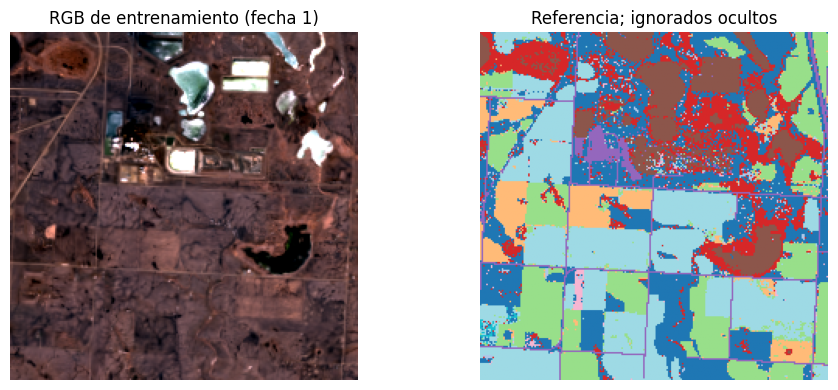

In [ ]:
samples={split:[read_sample(TASK,im,lab,crop_layout=CROP_LAYOUT) for im,lab in rows]
         for split,rows in pairs.items()}
for split,rows in samples.items():
    print(split,[(x.shape,y.shape,np.unique(y).tolist()) for x,y in rows])
    for x,y in rows:
        if not np.isin(y[y>=0],CLASSES).all(): raise ValueError('Etiqueta fuera de leyenda; revisar la versión.')
x0,y0=samples['train'][0]
def display_rgb(x):
    a=x[[2,1,0],0].transpose(1,2,0).copy()
    for c in range(3):
        v=a[:,:,c];finite=np.isfinite(v)
        if not finite.any():continue
        lo,hi=np.percentile(v[finite],[2,98]); a[:,:,c]=np.clip((v-lo)/max(hi-lo,1e-6),0,1)
    return np.nan_to_num(a)
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(display_rgb(x0));ax[0].set_title('RGB de entrenamiento (fecha 1)')
ax[1].imshow(np.ma.masked_where(y0<0,y0),vmin=min(CLASSES),vmax=max(CLASSES),cmap='tab20');ax[1].set_title('Referencia; ignorados ocultos')
for a in ax:a.axis('off')
fig.tight_layout();fig.savefig(OUT/'01_exploracion.png',dpi=150);plt.show()


### 3.1. Verificación de bandas espectrales y estructura temporal


In [ ]:

import rasterio
import numpy as np

imagen, etiqueta = pairs["train"][0]

with rasterio.open(imagen) as src:
    datos = src.read()
    print("Dimensiones:", datos.shape)
    print("Descripciones:", src.descriptions)
    print("Metadatos:", src.tags())

    for i in range(src.count):
        banda = datos[i]
        validos = banda[
            np.isfinite(banda) & (banda != -9999)
        ]

        media = (
            np.mean(validos)
            if validos.size
            else np.nan
        )

        print(f"Canal {i+1:02d}: media={media:.2f}")


Dimensiones: (18, 224, 224)
Descripciones: (None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None)
Metadatos: {'AREA_OR_POINT': 'Area'}
Canal 01: media=601.82
Canal 02: media=806.54
Canal 03: media=1035.65
Canal 04: media=1479.43
Canal 05: media=2283.83
Canal 06: media=1835.92
Canal 07: media=371.12
Canal 08: media=652.57
Canal 09: media=583.62
Canal 10: media=2873.54
Canal 11: media=2074.98
Canal 12: media=1300.45
Canal 13: media=468.90
Canal 14: media=800.14
Canal 15: media=878.27
Canal 16: media=2637.88
Canal 17: media=2406.63
Canal 18: media=1529.01


**Actividad:** registre canales, formas, leyenda, datos faltantes y correspondencia con la documentación. Explique qué información se pierde al usar solo el recorte central y qué podría cambiar al utilizar otras fechas o variables auxiliares.


## 4. Normalización sin fuga de prueba
Se estima media y desviación por banda **solo con imágenes de entrenamiento**, usando posiciones con etiqueta válida, sin usar su clase. Estas estadísticas se aplican a ambos conjuntos. Esto no es fine-tuning ni la normalización oficial original: es una decisión de transferencia que permite trabajar con distintas escalas, y debe mencionarse como limitación.

Imputación: los valores no finitos se convierten en cero después de estandarizar. No se evalúan posiciones inválidas.


In [ ]:
mean,std=train_normalization(samples['train'])
prepared={split:[(normalize(x,mean,std),y) for x,y in rows] for split,rows in samples.items()}
save_json(OUT/'normalizacion.json',{'method':'train_zscore_by_band','mean':mean.tolist(),'std':std.tolist()})
print('Media train:',mean,'| STD train:',std)


Media train: [ 538.66797  868.5415  1011.87054 2939.2002  2728.2146  1869.6556 ] | STD train: [309.29022 389.50067 626.3826  873.86383 949.66675 956.34503]


## 5. Descargar Prithvi y congelar el encoder
Se fija una revisión histórica del modelo EO-1.0-100M. Se regenera la codificación posicional fija cuando se cambia el número de fechas. Solo esas claves pueden faltar al cargar los pesos; cualquier incompatibilidad restante detiene el proceso.

El checkpoint se carga con `weights_only=True`; no habilite carga arbitraria si aparece un error. El forward del encoder no actualiza pesos. Los tokens espaciales se restauran al orden original porque MAE puede permutarlos incluso sin ocultar parches.


### 5.1. Adaptación y carga del encoder


In [ ]:

# Adaptación del cargador de Prithvi al YAML oficial

import ast
import inspect
from pathlib import Path
import prithvi_taller

# Leer el módulo original, no la función modificada en memoria
ruta_modulo = Path(prithvi_taller.__file__)
fuente = ruta_modulo.read_text(encoding="utf-8")

# Localizar la definición original de load_prithvi
arbol = ast.parse(fuente)

nodo = next(
    n for n in arbol.body
    if isinstance(n, ast.FunctionDef)
    and n.name == "load_prithvi"
)

codigo = ast.get_source_segment(fuente, nodo)

# Identificar el formato incompatible del YAML
original = (
    "args=dict(cfg['model_args']);"
    "args['num_frames']=num_frames"
)

corregido = (
    "args={k:v for k,v in cfg.items() "
    "if k in inspect.signature(klass.__init__).parameters "
    "and k!='self'};"
    "args['in_chans']=len(cfg['bands']);"
    "args['num_frames']=num_frames"
)

assert original in codigo, (
    "La función original cambió. Revisar antes de modificar."
)

# Agregar inspect a los imports de la función
codigo = codigo.replace(
    "import torch,yaml,sys,importlib.util",
    "import torch,yaml,sys,importlib.util,inspect"
)

# Adaptar la lectura de parámetros
codigo = codigo.replace(original, corregido)

# Registrar la función corregida en el módulo
exec(codigo, vars(prithvi_taller))

load_prithvi = prithvi_taller.load_prithvi

print("Función de carga corregida correctamente.")
print("Compatible con el YAML de Prithvi-EO-1.0-100M.")


Función de carga corregida correctamente.
Compatible con el YAML de Prithvi-EO-1.0-100M.


In [ ]:
T=prepared['train'][0][0].shape[1]
model,device,model_info=load_prithvi(ROOT/'modelo',num_frames=T)
provenance={'task':TASK,'model':model_info,'ntrain':NTRAIN,'ntest':NTEST,
 'classes':CLASSES,'crop_layout':CROP_LAYOUT,'crop':'center224_pad_ignore',
 'normalization':'train_zscore_by_band','head':'RandomForest, patch16 majority, frozen encoder',
 'packages':{p:version(p) for p in ['torch','torchvision','timm','numpy','scikit-learn','rasterio']}}
save_json(OUT/'procedencia.json',provenance)
print(model_info)


Prithvi.py: 0.00B [00:00, ?B/s]

Prithvi_100M_config.yaml:   0%|          | 0.00/541 [00:00<?, ?B/s]

Prithvi_100M.pt:   0%|          | 0.00/454M [00:00<?, ?B/s]

{'repo': 'ibm-nasa-geospatial/Prithvi-EO-1.0-100M', 'revision': '7b231fe5b0684e2ddd40c967fbc02e225ef77dc6', 'checkpoint': '/content/taller_cultivos/modelo/Prithvi_100M.pt', 'device': 'cuda', 'num_frames': 3}


In [ ]:

print("Dispositivo:", device)
print("Fechas:", model.patch_embed.num_frames)
print("Canales:", model.patch_embed.proj.in_channels)
print("Modelo en evaluación:", not model.training)
print(
    "Parámetros entrenables:",
    sum(p.requires_grad for p in model.parameters())
)

assert not model.training
assert all(not p.requires_grad for p in model.parameters())

print("Encoder congelado correctamente.")


Dispositivo: cuda
Fechas: 3
Canales: 6
Modelo en evaluación: True
Parámetros entrenables: 0
Encoder congelado correctamente.


## 6. Entrenar exclusivamente la cabeza ligera
Cada parche 16×16 recibe la clase mayoritaria si ≥50% de sus etiquetas son válidas. Los empates se resuelven por el primer código en orden ascendente. El Random Forest opera sobre los embeddings de Prithvi. En cultivos se promedian los tokens de las fechas **después de la atención espaciotemporal**.

No se cambia ningún peso del encoder. Se conserva el conjunto de evaluación sin usarlo para elegir hiperparámetros. Si el subconjunto de entrenamiento no contiene una clase, el clasificador no puede aprenderla; se informa el problema, no se buscan escenas para mejorar la nota.


In [ ]:
train_features=[];train_targets=[]
for i,(x,y) in enumerate(prepared['train']):
    f=features(model,device,x);label=patch_labels(y)
    valid=label>=0
    train_features.append(f[valid]);train_targets.append(label[valid])
    print('Entrenamiento escena',i,'parches válidos:',valid.sum())
X=np.concatenate(train_features);Y=np.concatenate(train_targets)
if len(Y)==0:raise ValueError('No hay parches de entrenamiento válidos.')
print('Distribución de etiquetas por parche:',np.unique(Y,return_counts=True))
missing=sorted(set(CLASSES)-set(np.unique(Y)))
if missing:print('LIMITACIÓN: clases ausentes del entrenamiento:',missing)
head=RandomForestClassifier(n_estimators=80,max_depth=10,class_weight='balanced',random_state=42,n_jobs=2)
head.fit(X,Y)
# Baseline: clase de píxel más frecuente SOLO en entrenamiento.
train_labels=np.concatenate([y[y>=0] for _,y in samples['train']])
values,counts=np.unique(train_labels,return_counts=True)
majority=int(values[np.argmax(counts)])
print('Línea base constante:',majority)


Entrenamiento escena 0 parches válidos: 196
Entrenamiento escena 1 parches válidos: 196
Entrenamiento escena 2 parches válidos: 196
Entrenamiento escena 3 parches válidos: 196
Distribución de etiquetas por parche: (array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]), array([173,  50, 132, 109,  62,  39,  20,  35,   7,  33,  14,  21,  89]))
Línea base constante: 1


## 7. Evaluar el modelo y la línea base
La clase predicha por parche se expande a 16×16 mediante repetición. Es una máscara gruesa; no implica resolución efectiva de un píxel. Se compara con la referencia original sobre posiciones válidas.

Se acumulan matrices de confusión globales por píxel; además se guardan métricas por escena. No se interpreta el conjunto de píxeles como observaciones geográficas independientes. Las clases ausentes de referencia y predicción tienen métrica no definida y se excluyen del promedio macro; las clases presentes con omisiones sí se penalizan.


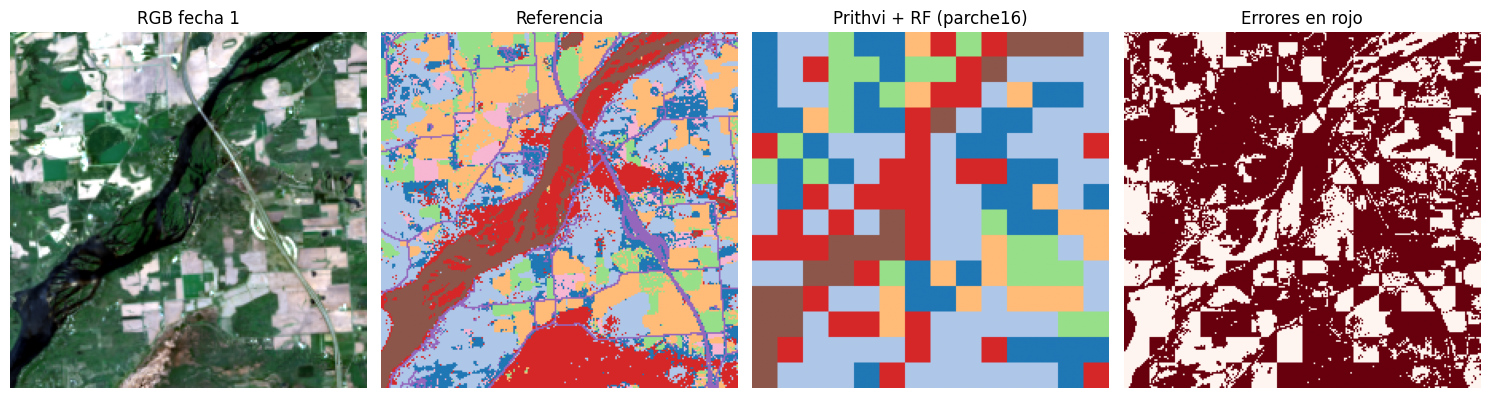

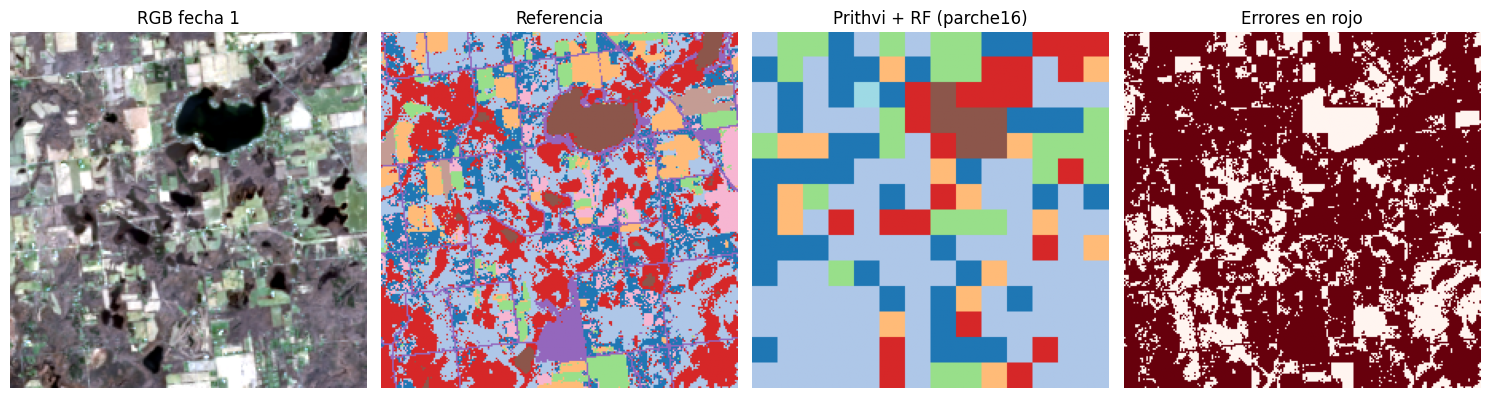

,method,f1_macro,miou
0,prithvi_rf,0.174211,0.110829
1,baseline,0.018262,0.010255


,method,class,support,iou,f1,precision,recall
0,prithvi_rf,1,12349,0.143635,0.251190,0.202284,0.331282
1,prithvi_rf,2,25054,0.298154,0.459350,0.375634,0.591083
2,prithvi_rf,3,13217,0.133291,0.235228,0.307373,0.190512
3,prithvi_rf,4,6682,0.162770,0.279969,0.221181,0.381323
4,prithvi_rf,5,21066,0.134186,0.236621,0.286166,0.201699
5,prithvi_rf,6,8954,0.000000,0.000000,0.000000,0.000000
6,prithvi_rf,7,6650,0.457907,0.628170,0.668818,0.592180
7,prithvi_rf,8,983,0.000000,0.000000,0.000000,0.000000
8,prithvi_rf,9,5090,0.000000,0.000000,0.000000,0.000000
9,prithvi_rf,10,85,0.000000,0.000000,0.000000,0.000000


In [ ]:
totals={'prithvi_rf':np.zeros((len(CLASSES),len(CLASSES)),dtype=np.int64),
        'baseline':np.zeros((len(CLASSES),len(CLASSES)),dtype=np.int64)}
scene_rows=[]
for i,((x,y),(raw,_)) in enumerate(zip(prepared['test'],samples['test'])):
    f=features(model,device,x)
    grid=head.predict(f.reshape(-1,f.shape[-1])).reshape(14,14)
    pred=np.repeat(np.repeat(grid,16,axis=0),16,axis=1)
    baseline=np.full(y.shape,majority,dtype=np.int64)
    for name,p in [('prithvi_rf',pred),('baseline',baseline)]:
        mat=confusion(y,p,CLASSES);totals[name]+=mat
        for row in metrics(mat,CLASSES):scene_rows.append({'scene':i,'method':name,**row})
    np.savez_compressed(OUT/f'escena_{i}.npz',label=y,prediction=pred,baseline=baseline)
    fig,ax=plt.subplots(1,4,figsize=(15,4))
    ax[0].imshow(display_rgb(raw));ax[0].set_title('RGB fecha 1')
    ax[1].imshow(np.ma.masked_where(y<0,y),vmin=min(CLASSES),vmax=max(CLASSES),cmap='tab20');ax[1].set_title('Referencia')
    ax[2].imshow(np.ma.masked_where(y<0,pred),vmin=min(CLASSES),vmax=max(CLASSES),cmap='tab20');ax[2].set_title('Prithvi + RF (parche16)')
    ax[3].imshow(np.ma.masked_where(y<0,(pred!=y).astype(float)),vmin=0,vmax=1,cmap='Reds');ax[3].set_title('Errores en rojo')
    for a in ax:a.axis('off')
    fig.tight_layout();fig.savefig(OUT/f'02_resultado_{i}.png',dpi=150);plt.show()
rows=[]
for name,mat in totals.items():
    for row in metrics(mat,CLASSES):rows.append({'method':name,**row})
    pd.DataFrame(mat,index=CLASSES,columns=CLASSES).to_csv(OUT/f'confusion_{name}.csv')
byclass=pd.DataFrame(rows);byclass.to_csv(OUT/'metricas_por_clase.csv',index=False)
pd.DataFrame(scene_rows).to_csv(OUT/'metricas_por_escena.csv',index=False)
summary=[]
for name in totals:
    subset=byclass[byclass.method==name]
    if TASK=='cultivos':
        summary.append({'method':name,'f1_macro':subset.f1.mean(),'miou':subset.iou.mean()})
    else:
        pos=subset[subset['class']==1].iloc[0]
        summary.append({'method':name,'f1_positive':pos.f1,'iou_positive':pos.iou,'precision':pos.precision,'recall':pos.recall})
summary=pd.DataFrame(summary);summary.to_csv(OUT/'metricas.csv',index=False)
display(summary);display(byclass)


### 7.1. Matriz de confusión


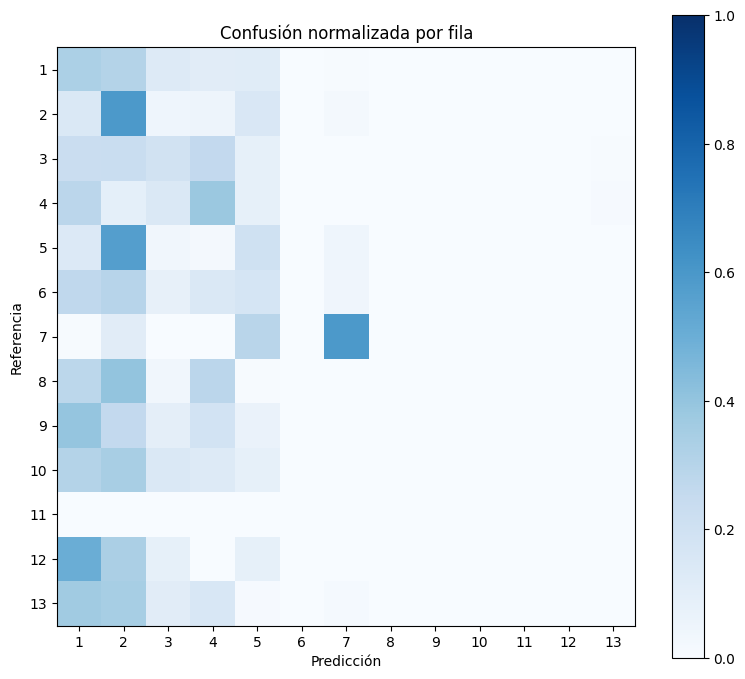

In [ ]:
fig,ax=plt.subplots(figsize=(8,7))
cm=totals['prithvi_rf'];row_sum=cm.sum(axis=1,keepdims=True)
normalized_cm=np.divide(cm,row_sum,out=np.zeros_like(cm,dtype=float),where=row_sum!=0)
im=ax.imshow(normalized_cm,vmin=0,vmax=1,cmap='Blues');fig.colorbar(im,ax=ax)
ax.set(xticks=range(len(CLASSES)),yticks=range(len(CLASSES)),xticklabels=CLASSES,yticklabels=CLASSES,
       xlabel='Predicción',ylabel='Referencia',title='Confusión normalizada por fila')
fig.tight_layout();fig.savefig(OUT/'03_matriz_confusion.png',dpi=150);plt.show()


### 7.2. Métricas por clase


In [ ]:

import pandas as pd
from IPython.display import display

ruta = OUT / "metricas_por_clase.csv"

df = pd.read_csv(ruta)

print("Columnas disponibles:", df.columns.tolist())
print("\nResultados por clase:")
display(df)

print("\nClases evaluadas:", df.shape[0])


Columnas disponibles: ['method', 'class', 'support', 'iou', 'f1', 'precision', 'recall']

Resultados por clase:


,method,class,support,iou,f1,precision,recall
0,prithvi_rf,1,12349,0.143635,0.251190,0.202284,0.331282
1,prithvi_rf,2,25054,0.298154,0.459350,0.375634,0.591083
2,prithvi_rf,3,13217,0.133291,0.235228,0.307373,0.190512
3,prithvi_rf,4,6682,0.162770,0.279969,0.221181,0.381323
4,prithvi_rf,5,21066,0.134186,0.236621,0.286166,0.201699
5,prithvi_rf,6,8954,0.000000,0.000000,0.000000,0.000000
6,prithvi_rf,7,6650,0.457907,0.628170,0.668818,0.592180
7,prithvi_rf,8,983,0.000000,0.000000,0.000000,0.000000
8,prithvi_rf,9,5090,0.000000,0.000000,0.000000,0.000000
9,prithvi_rf,10,85,0.000000,0.000000,0.000000,0.000000



Clases evaluadas: 26


### 7.3. Principales confusiones y exactitud global


In [ ]:

import pandas as pd
import numpy as np

ruta = OUT / "confusion_prithvi_rf.csv"
df = pd.read_csv(ruta, index_col=0)

matriz = df.to_numpy()
etiquetas = df.index.astype(str).tolist()

errores = []

for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        if i != j and matriz[i, j] > 0:
            errores.append({
                "Clase real": etiquetas[i],
                "Predicha como": etiquetas[j],
                "Píxeles confundidos": int(matriz[i, j])
            })

errores_df = pd.DataFrame(errores)

errores_df = errores_df.sort_values(
    "Píxeles confundidos",
    ascending=False
)

print("Principales confusiones del modelo:")
display(errores_df.head(10))

total = matriz.sum()
correctos = np.trace(matriz)
incorrectos = total - correctos

print("\nPíxeles evaluados:", total)
print("Píxeles correctos:", correctos)
print("Píxeles incorrectos:", incorrectos)
print(f"Exactitud global: {correctos / total:.4f}")


Principales confusiones del modelo:


,Clase real,Predicha como,Píxeles confundidos
25,5,2,11932
0,1,2,3795
9,2,5,3756
6,2,1,3529
14,3,4,3419
13,3,2,3077
12,3,1,3024
24,5,1,2861
31,6,2,2655
30,6,1,2395



Píxeles evaluados: 100352
Píxeles correctos: 32153
Píxeles incorrectos: 68199
Exactitud global: 0.3204


### 7.4. Inspección visual de las predicciones


Figuras encontradas: 2

Archivo: 02_resultado_0.png


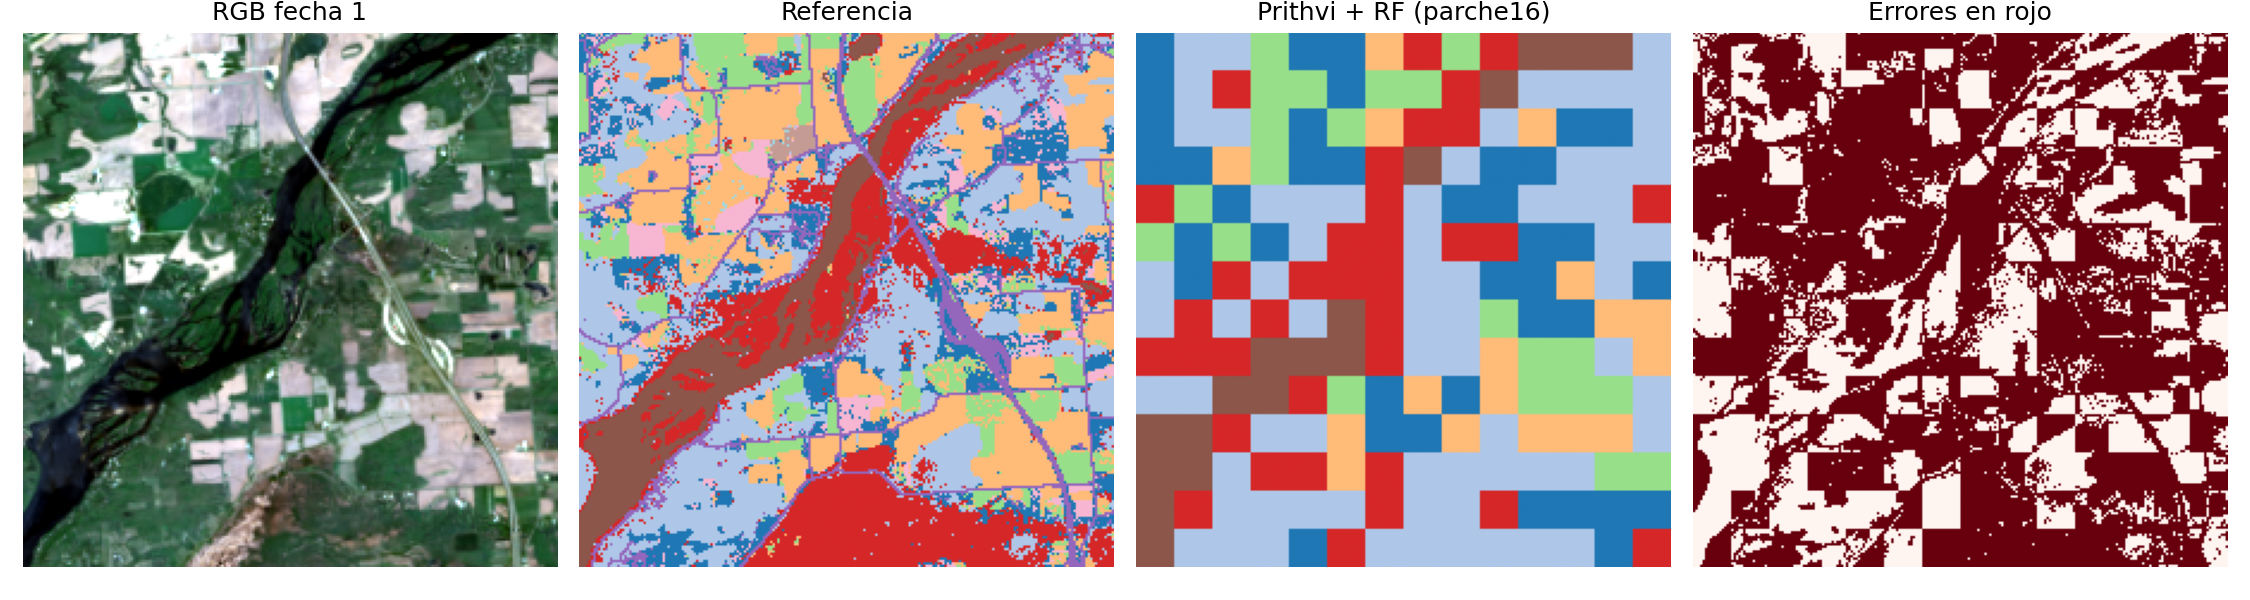


Archivo: 02_resultado_1.png


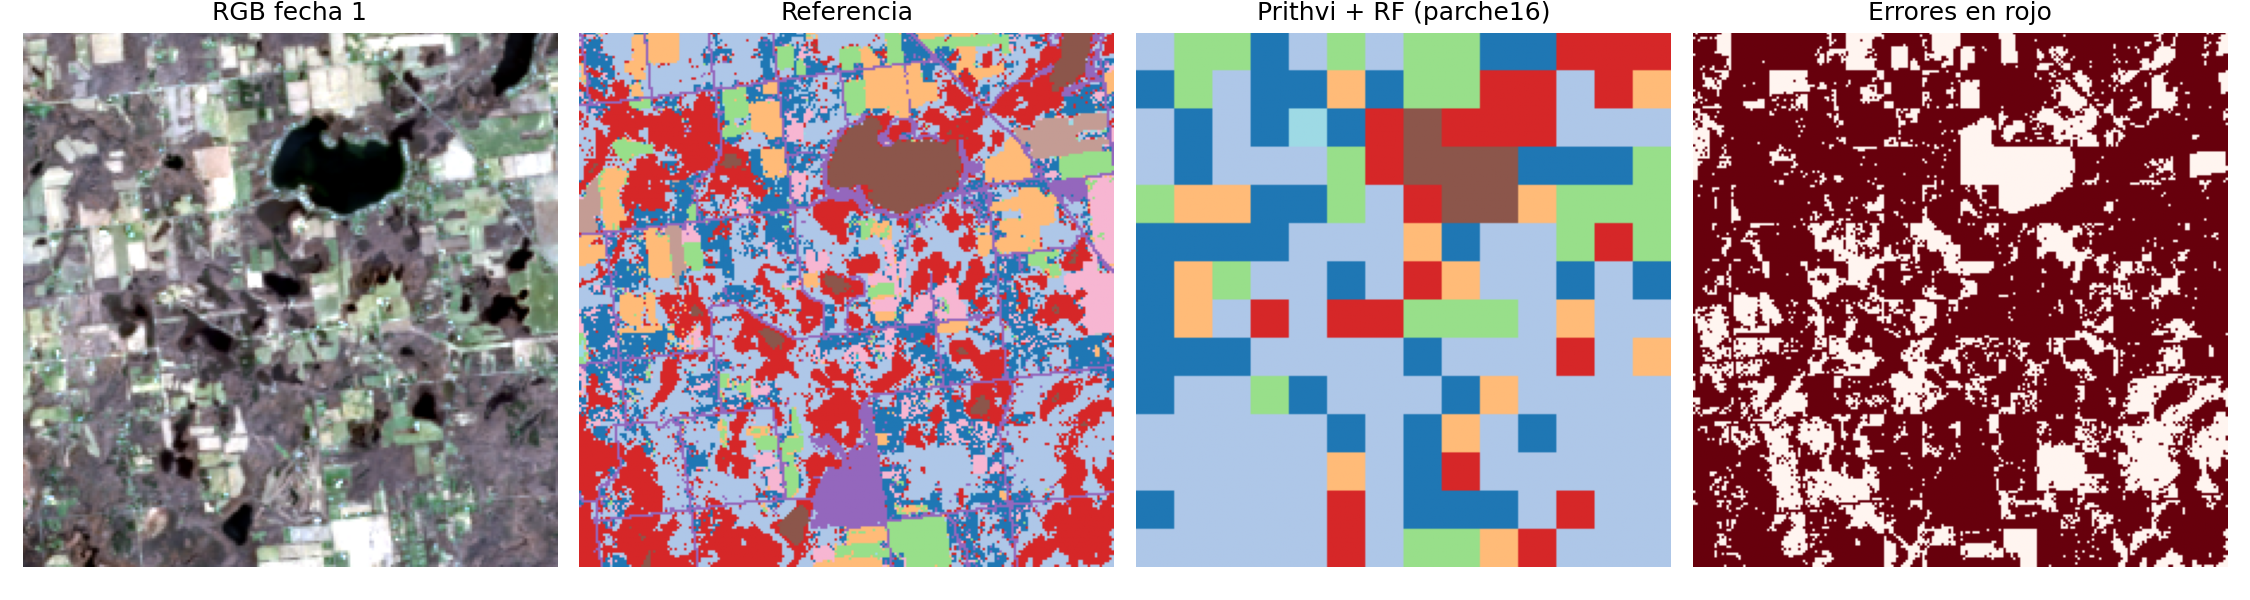

In [ ]:

from pathlib import Path
from IPython.display import display, Image

# Buscar las figuras de resultados generadas
figuras = sorted(OUT.glob("*resultado*.png"))

print("Figuras encontradas:", len(figuras))

for figura in figuras:
    print("\nArchivo:", figura.name)
    display(Image(filename=str(figura)))


## 8. Trabajo del grupo
1. Explique el problema y la definición de sus clases; identifique el origen de los datos.
2. Justifique por qué este pipeline es **transferencia con encoder congelado**, no un modelo especializado oficial ni fine-tuning completo.
3. Describa y critique la normalización, selección de bandas, recorte, agregación temporal si existe y predicción por parche.
4. Compare modelo y baseline con valores reales; no está garantizado que el modelo gane.
5. Identifique falsos positivos y falsos negativos. Si no existen para una clase/muestra, declárelo sin inventar ejemplos.
6. Discuta clases ausentes y desbalance. ¿Cuánto limita el entrenamiento con cuatro escenas?
7. Proponga una aplicación en Colombia y qué validación adicional necesita.
8. Responda las preguntas de la ficha de su grupo y declare quién ejecutó cada parte.

**Extensiones opcionales:** más
 fijadas previamente, control con features espectrales + el mismo clasificador, o normalización/preprocesamiento oficial tras verificar compatibilidad. No cambie el método en función de resultados de prueba.


# 1. Problema, definición de clases y origen de los datos

**Problema.** Se trata de una clasificación multitemporal de la cobertura y el uso del suelo agrícola a partir de imágenes satelitales: para cada zona de la imagen se predice qué cultivo o cobertura tiene. Se usan **tres fechas de la misma temporada** porque los cultivos se distinguen más por cómo cambian durante el ciclo (siembra, crecimiento, cosecha) que por su aspecto en una sola fecha.

**Datos.** Se usa el dataset *Multi-Temporal Crop Classification* de IBM–NASA (Hugging Face: `ibm-nasa-geospatial/multi-temporal-crop-classification`), con imágenes HLS (*Harmonized Landsat Sentinel-2*) a $30\ \text{m}$ sobre Estados Unidos (temporada 2022). Las etiquetas provienen del *Cropland Data Layer* (CDL) del USDA.

| Característica | Valor |
|---|---|
| Tamaño del chip | $224 \times 224$ píxeles |
| Canales | $18 = 6 \text{ bandas} \times 3 \text{ fechas}$ |
| Bandas | azul, verde, rojo, NIR estrecho, SWIR1, SWIR2 |
| Layout configurado | `CROP_LAYOUT='TC'` (fecha–banda) |

Las medias por canal confirman el layout: en cada bloque de 6 canales el NIR es alto y, del primer al segundo bloque, sube de $\approx 1479$ a $\approx 2873$, lo que indica crecimiento de la vegetación.

**Partición.** Se usó el split del proveedor:

- **Entrenamiento** (`training_chips`, 4 escenas): `chip_067_292`, `chip_156_480`, `chip_212_445`, `chip_251_271`.
- **Prueba** (`validation_chips`, 2 escenas): `chip_131_428`, `chip_143_480`.

La selección se hizo por orden de aparición, no por desempeño.

**Clases.** Son los códigos $1$ a $13$ de la referencia; el código $0$ es *nodata* y se ignora. Según la documentación del dataset:

| Código | Clase | Código | Clase |
|:---:|---|:---:|---|
| 1 | Vegetación natural | 8 | Trigo de invierno |
| 2 | Bosque | 9 | Alfalfa |
| 3 | Maíz | 10 | Tierra en barbecho/ociosa |
| 4 | Soya | 11 | Algodón |
| 5 | Humedales | 12 | Sorgo |
| 6 | Urbano/suelo desnudo | 13 | Otros |
| 7 | Agua | | |

> *Esta leyenda debe confirmarse para la versión descargada.*

En el entrenamiento aparecen las 13 clases, pero con **fuerte desbalance** (en parches): clase 1 $= 173$, clase 3 $= 132$, clase 4 $= 109$, clase 13 $= 89$; en el otro extremo, clase 9 $= 7$, clase 11 $= 14$ y clase 7 $= 20$.

---

# 2. Por qué es transferencia con encoder congelado y no un modelo especializado ni *fine-tuning*

**Modelo fundacional general.** Prithvi-EO-1.0-100M es un autoencoder enmascarado (MAE, basado en ViT) preentrenado de forma autosupervisada sobre imágenes HLS. Su objetivo fue reconstruir parches ocultos, **no** clasificar cultivos. Se cargó la revisión fija `7b231fe…` con `weights_only=True`.

**Encoder congelado.** El modelo está en modo evaluación (`model.eval()`), con `requires_grad=False` en todos sus parámetros, y la extracción se hace bajo `torch.inference_mode()`. La verificación de la celda lo confirma:

$$\text{Parámetros entrenables} = 0$$

Ningún peso de Prithvi cambia durante el experimento.

**Cabeza ligera externa.** Solo se entrena un *Random Forest* (80 árboles, profundidad 10, `class_weight='balanced'`) sobre los embeddings de Prithvi. No se usa el decoder de segmentación ni se entrena por retropropagación.

**Por qué no es *fine-tuning* completo.** En un fine-tuning se ajustan los pesos del encoder (o de una parte) junto con un decoder, usando las etiquetas de cultivos. Aquí el encoder es solo un extractor fijo de características.

**Por qué no es el modelo especializado oficial.** IBM–NASA publicó un checkpoint de Prithvi ajustado para esta tarea, con decoder de segmentación por píxel y preprocesamiento propio. Aquí **no** se usa ese checkpoint. Además, solo se regeneró la codificación posicional (`pos_embed`) para el número de fechas, y la normalización no es la oficial. Por eso los resultados **no** pueden presentarse como una evaluación del modelo oficial.

---

# 3. Descripción y crítica de la metodología

## Normalización

Se calcula un *z-score* por banda, con media y desviación estándar agrupando las 3 fechas:

$$z_b = \frac{x_b - \mu_b}{\sigma_b}$$

Las estadísticas $\mu_b, \sigma_b$ se estiman **solo** con las 4 escenas de entrenamiento y solo en posiciones con etiqueta válida, y luego se aplican igual a entrenamiento y prueba. Los valores no finitos se reemplazan por $0$ tras estandarizar.

- **A favor:** evita la fuga de información del conjunto de prueba.
- **En contra:**
  - Con 4 escenas, las estadísticas son poco representativas.
  - No coinciden con la media y desviación del preentrenamiento de Prithvi, así que el encoder recibe entradas con una distribución distinta a la que conoció.
  - Juntar las 3 fechas mezcla estados fenológicos distintos.
  - Imputar $0$ equivale a imputar la media, lo que puede introducir un sesgo leve.

## Selección de bandas

Se usan las 6 bandas ópticas (azul, verde, rojo, NIR estrecho, SWIR1, SWIR2), equivalentes en significado a las del preentrenamiento HLS. Sin embargo, el GeoTIFF no trae descripciones de canales (`Descripciones: None`), por lo que **el orden de las bandas y el layout `TC` dependen de la documentación**. Además, hay una discrepancia sin resolver entre las bandas del dataset y las que espera el checkpoint. Si el orden fuera incorrecto, los embeddings serían poco significativos **sin que el código arrojara ningún error**.

## Recorte

El pipeline toma un recorte central de $224 \times 224$ y rellena los bordes si la imagen es más pequeña. Aquí los chips ya tienen forma $(18, 224, 224)$, así que el recorte no descarta información. Con escenas más grandes se perdería la periferia y se tomaría una sola muestra por escena.

## Agregación temporal

Las 3 fechas entran juntas al encoder (`num_frames=3`), por lo que la atención espacio-temporal sí las relaciona. Pero después se **promedian los tokens de las 3 fechas**:

$$\bar{\mathbf{h}} = \frac{1}{3}\sum_{t=1}^{3} \mathbf{h}_t$$

Este promedio borra el orden y la dinámica temporal (por ejemplo, cuándo alcanza su pico de verdor cada cultivo), que es justo lo que separa clases como maíz, soya o trigo de invierno. Concatenar los tokens por fecha, $[\mathbf{h}_1;\mathbf{h}_2;\mathbf{h}_3]$, conservaría mejor esa información.

## Predicción por parche

Cada parche de $16 \times 16$ píxeles ($\approx 480 \times 480\ \text{m}$ a $30\ \text{m}$) recibe la clase mayoritaria, siempre que al menos el $50\%$ de sus píxeles sean válidos. El RF predice $14 \times 14 = 196$ parches por escena, y esa predicción se expande por repetición para compararla píxel a píxel.

**Consecuencias:**

- El resultado es una **máscara gruesa**: las parcelas pequeñas y los bordes entre cultivos se asignan mal por construcción.
- Las clases minoritarias dentro de un parche desaparecen ya en el entrenamiento.
- Los empates se resuelven a favor del código más bajo, lo que sesga hacia las clases 1 a 3.
- Por eso, parte del error medido viene de la **resolución del método** y no del encoder.

## Tamaño de la muestra

Solo hay $784$ parches de entrenamiento, muy desbalanceados (la clase 9 tiene apenas $7$), lo que limita lo que puede aprender el Random Forest. Esto se discute más a fondo en la sección 8.2.


# 8.2 Comparación con la línea base, errores por clase y límites del entrenamiento

## Modelo frente a línea base

La línea base predice, para todos los píxeles de prueba, la clase más frecuente en los píxeles de entrenamiento. La comparación usa las mismas posiciones válidas: unos $100.350$ píxeles ($32.153 / 0{,}3204$).

Con una predicción constante, solo la clase predicha tiene $F_1 > 0$. Las otras 11 clases presentes en prueba tienen $F_1 = 0$ y **sí** cuentan en el promedio. Algodón queda fuera porque su métrica no está definida.

| Método | Exactitud | $F_1$ macro | mIoU |
|---|:---:|:---:|:---:|
| **Prithvi + RF** | **32,04 %** | **0,1742** | **0,1108** |
| Baseline = clase 1, Vegetación natural ($\approx 12.362$ px) | 12,3 % | 0,018 | 0,010 |
| Baseline = clase 2, Bosque ($\approx 25.054$ px, la más frecuente en prueba) | 25,0 % | 0,033 | 0,021 |

**Lectura.**

- El modelo supera al baseline en las tres métricas, aunque el margen es pequeño.
- En exactitud gana por unos $7$ puntos incluso contra la mejor constante posible (Bosque). Ninguna constante puede pasar del $25\,\%$ en este conjunto de prueba.
- La ventaja real está en $F_1$ macro y mIoU: el modelo acierta en varias clases, mientras que la constante acierta en una sola.
- Aun así, un $32\,\%$ de exactitud es bajo en términos absolutos. El modelo es mejor que no aprender nada, pero **no es útil en la práctica**.
- Casi la mitad de los aciertos son de Bosque: unos $14.800$ de $32.153$ ($46\,\%$). El modelo gana sobre todo por acertar coberturas naturales grandes, no cultivos.

---

## Falsos positivos y falsos negativos

Los valores salen de la matriz `confusion_prithvi_rf.csv`, a nivel de píxel. El **FN** de una clase son sus píxeles predichos como otra clase; el **FP** son píxeles de otras clases predichos como ella.

| Clase | Falsos negativos (FN) | Falsos positivos (FP) |
|---|---|---|
| **Bosque (2)** | $3.756 \to$ Humedales; $3.529 \to$ Vegetación natural | $\geq 21.459$: $11.932$ de Humedales, $3.795$ de Vegetación natural, $3.077$ de Maíz, $2.655$ de Urbano. Precisión $\leq 41\,\%$ |
| **Humedales (5)** | $\approx 14.800$ o más: $11.932 \to$ Bosque ($56{,}6\,\%$), $2.861 \to$ Vegetación natural. Recall $\leq 30\,\%$ | no disponible con los datos actuales |
| **Maíz (3)** | $\geq 9.520$: $\to$ Soya $3.419$, $\to$ Bosque $3.077$, $\to$ Vegetación natural $3.024$. Recall $\leq 28\,\%$ | no disponible con los datos actuales |
| **Vegetación natural (1)** | $\geq 3.795 \to$ Bosque ($30{,}7\,\%$) | $3.529$ de Bosque, $3.024$ de Maíz, $2.861$ de Humedales, $2.395$ de Urbano |
| **Urbano/suelo desnudo (6)** | $8.954$ (todos sus píxeles; $F_1 = 0$) | no se pueden saber con lo disponible |
| **Alfalfa (9)** | $5.090$ (todos sus píxeles; $F_1 = 0$) | no se pueden saber con lo disponible |
| **Trigo de invierno, Barbecho, Sorgo y Otros (8, 10, 12, 13)** | $1.290$ en total (todos sus píxeles; $F_1 = 0$) | no se pueden saber con lo disponible |
| **Algodón (11)** | ninguno | ninguno |

**Notas.**

- **Maíz** presenta la confusión entre cultivos más importante (Maíz $\to$ Soya).
- **Urbano y Alfalfa** tienen $0$ verdaderos positivos. Para conocer sus FP hay que revisar la columna de cada clase en la matriz.
- **Algodón** no está en la referencia de prueba (soporte $0$) y el modelo nunca lo predijo, por lo que su métrica quedó indefinida. No se puede dar ningún ejemplo de FP ni de FN.
- **Línea base.** La clase constante tiene $\text{FN} = 0$ y $\text{FP} =$ todos los demás píxeles. Las demás clases tienen $\text{FP} = 0$ y $\text{FN}$ igual a todo su soporte.
- **Por escena.** El desglose está en `metricas_por_escena.csv` y en las figuras `02_resultado_0/1.png`. No se reportan cifras por escena aquí.

---

## Clases ausentes y desbalance

### Clases ausentes

- En el entrenamiento aparecen las 13 clases a nivel de parche, así que ninguna quedó fuera del Random Forest.
- En prueba falta **Algodón** (soporte $0$). Su capacidad de detección no se evaluó, y eso no significa que funcione bien.
- Ocurre lo contrario con **Urbano** y **Alfalfa**: sí están en prueba ($8.954$ y $5.090$ píxeles) y el modelo nunca las acierta. Estar en el entrenamiento no garantiza aprenderlas.

### Desbalance

- En parches de entrenamiento va de $173$ (clase 1) a $7$ (Alfalfa), unas $25$ veces de diferencia. Algodón tiene $14$, Agua $20$, Sorgo $21$ y Barbecho $33$.
- `class_weight='balanced'` da más peso a esos $7$ parches, pero no crea más variedad: el árbol los memoriza y no generaliza.
- La etiqueta mayoritaria por parche borra las clases minoritarias dentro de cada parche de $16 \times 16$, y los empates favorecen los códigos bajos.
- En prueba el desbalance es distinto (Humedales pesa $\approx 21\,\%$). Ese **cambio de distribución** entre entrenamiento y prueba también afecta.

---

## ¿Cuánto limita entrenar con cuatro escenas?

**Mucho, y probablemente es la limitación principal.**

1. **Muestra efectiva.** Los $784$ parches salen de solo $4$ lugares. Los parches de una misma escena comparten fecha, suelo, clima y manejo, así que no son observaciones independientes. El tamaño de muestra efectivo se parece más a $4$ que a $784$.
2. **Clases raras.** Una clase con $7$ parches casi seguro viene de una sola escena. El RF aprende cómo se ve esa clase *en ese sitio*, no cómo se ve en general.
3. **Varianza en prueba.** La prueba son solo $2$ escenas, por lo que las métricas tienen mucha varianza. Cambiar una sola escena podría mover bastante la exactitud y el $F_1$.
4. **Causas confundidas.** Con este diseño no se puede saber cuánto del $32\,\%$ viene de la falta de datos y cuánto de otros límites: la diferencia de bandas con el checkpoint, la normalización no oficial y el promedio de las fechas.

**Cómo medirlo.** Entrenar con más escenas **fijadas de antemano**, sin elegirlas según el resultado en prueba, y observar cómo cambia el $F_1$ macro.


# 8.3 Preguntas de análisis

## 8. ¿Por qué puede ser útil observar el mismo lugar en varias fechas?

Porque un cultivo se reconoce por **cómo cambia durante su ciclo**, no solo por cómo se ve un día cualquiera. Con una sola imagen, dos cultivos distintos pueden verse casi iguales (por ejemplo, maíz y soya cuando ambos están bien verdes). Con varias fechas se notan diferencias como:

- cuándo reverdece cada cultivo,
- cuándo llega a su punto máximo,
- cuándo se cosecha.

Además, si una fecha tiene nubes, sombras o algo raro, las otras ayudan a compensarla.

**En nuestro experimento.** Cada escena tiene $3$ fechas con $6$ bandas cada una, es decir $18$ canales, organizados con `CROP_LAYOUT='TC'`. Prithvi procesa las tres fechas juntas, pero después **promediamos los tokens de las fechas** antes de pasarlos al Random Forest. Ese promedio puede borrar parte de la información temporal y es una limitación de nuestro diseño.

Aun así, la ventaja de usar varias fechas no se ve con claridad en los resultados, porque el modelo igual confunde cultivos que se comportan distinto en el tiempo. Creemos que esto se debe más a otras limitaciones que a que las fechas no sirvan:

- las pocas escenas de entrenamiento,
- la diferencia entre las bandas del dataset y las del checkpoint,
- una normalización distinta a la oficial.

---

## 9. ¿Qué pares de clases se confunden con mayor frecuencia según su matriz?

Según la matriz de confusión del modelo (`confusion_prithvi_rf.csv`, graficada normalizada por fila en `03_matriz_confusion.png`), los pares más confundidos son:

| Clase real $\to$ predicha | Píxeles confundidos | % de la clase real |
|---|--:|--:|
| 5 Wetlands $\to$ 2 Forest | $11.932$ | $56{,}6\,\%$ |
| 1 Natural Vegetation $\to$ 2 Forest | $3.795$ | $30{,}7\,\%$ |
| 2 Forest $\to$ 5 Wetlands | $3.756$ | $15{,}0\,\%$ |
| 2 Forest $\to$ 1 Natural Vegetation | $3.529$ | $14{,}1\,\%$ |
| 3 Corn $\to$ 4 Soybeans | $3.419$ | $25{,}9\,\%$ |
| 3 Corn $\to$ 2 Forest | $3.077$ | $23{,}3\,\%$ |
| 3 Corn $\to$ 1 Natural Vegetation | $3.024$ | $22{,}9\,\%$ |
| 5 Wetlands $\to$ 1 Natural Vegetation | $2.861$ | $13{,}6\,\%$ |
| 6 Developed/Barren $\to$ 2 Forest | $2.655$ | $29{,}7\,\%$ |
| 6 Developed/Barren $\to$ 1 Natural Vegetation | $2.395$ | $26{,}7\,\%$ |

**Lectura.**

- **La confusión más grande** es humedales predichos como bosque: más de la mitad de los píxeles de humedales ($56{,}6\,\%$) terminaron clasificados como bosque.
- **Las clases 1, 2 y 5** (vegetación natural, bosque y humedales) se mezclan entre sí. Tiene sentido: son coberturas verdes con aspecto espectral y textura parecidos.
- **Maíz y soya**, dos cultivos de verano muy parecidos, también se confunden. Es justo el tipo de dificultad que la ficha pide investigar: clases con aspecto espectral semejante.
- **Bosque como clase refugio.** Recibe errores de muchas otras clases y además es la de mayor soporte, con $25.054$ píxeles.

---

## 10. ¿Por qué una exactitud global alta puede ocultar un desempeño bajo en cultivos minoritarios?

La exactitud global solo cuenta cuántos píxeles se acertaron del total, y cada píxel pesa lo mismo. Por eso **las clases grandes mandan** en el resultado: una clase que ocupa el $1\,\%$ del área puede fallar por completo y la exactitud casi no se mueve. El $F_1$ por clase y el $F_1$ macro sí lo notan, porque dan el mismo peso a cada clase.

**En nuestro experimento:**

1. **Clases con $F_1 = 0$.** Winter Wheat, Fallow/Idle Cropland, Sorghum y Other suman solo $1.290$ píxeles, el $1{,}3\,\%$ del total. Sin ellas la exactitud casi no cambiaría, pero el $F_1$ macro sí.
2. **Los aciertos se concentran.** De los $32.153$ píxeles acertados, unos $14.800$ son de Forest (casi el $46\,\%$). Forest y Open Water aportan buena parte del acierto, mientras que **seis clases no aportan nada**: Developed/Barren, Winter Wheat, Alfalfa, Fallow/Idle Cropland, Sorghum y Other.
3. **No es solo un problema de clases diminutas.** Developed/Barren y Alfalfa tienen $8.954$ y $5.090$ píxeles de soporte y aun así su $F_1$ es $0$.
4. **El desbalance viene desde el entrenamiento.** Alfalfa tiene solo $7$ parches; Cotton, Sorghum y Fallow/Idle Cropland tienen $14$, $21$ y $33$. Aunque usamos `class_weight='balanced'`, el Random Forest tiene muy pocos ejemplos para aprenderlas.
5. **Cotton** no aparece en el conjunto de prueba (soporte $0$), así que su métrica queda indefinida y no entra en el promedio macro.

En nuestro caso la exactitud ya es baja ($32{,}04\,\%$), así que el efecto se ve de otra forma: el $F_1$ macro de $0{,}1742$ muestra que la mayoría de las clases tiene un desempeño nulo o muy bajo. Con una exactitud del $90\,\%$ este mismo problema podría pasar sin que nadie lo notara. Por eso reportamos $F_1$ macro, $F_1$ e IoU por clase y el soporte de cada clase junto con la exactitud.

---

## 11. ¿Qué limita transferir un modelo entre países, calendarios agrícolas o conjuntos de clases distintos?

1. **Cambio de dominio espectral.** El sensor, el procesamiento HLS, la corrección atmosférica y el orden de las bandas deben coincidir con los del preentrenamiento. En nuestro experimento sigue habiendo una diferencia entre las bandas del dataset y las del checkpoint, y la normalización con estadísticas de entrenamiento no es la oficial.
2. **Calendario agrícola y fenología.** El modelo aprendió ciclos de una región con estaciones bien marcadas (el dataset es de Estados Unidos). En Colombia hay dos temporadas de lluvia, siembras escalonadas y cultivos con varias cosechas al año. Las $3$ fechas pueden caer en etapas del ciclo muy distintas y el modelo no sabría interpretarlas.
3. **Conjunto de clases.** El clasificador solo conoce las $13$ clases de entrenamiento. Cultivos como café, plátano, palma de aceite o caña no existen en su leyenda. Aunque el encoder se reutilice, hay que reentrenar la cabeza con nuevas etiquetas, y la definición de cada clase puede cambiar de un país a otro.
4. **Tamaño y estructura de las parcelas.** Con $30\ \text{m}$ de resolución y parches de $16 \times 16$ píxeles, las parcelas pequeñas, los cultivos asociados y los lotes irregulares de la agricultura de pequeña escala se mezclan dentro de un mismo parche, lo que genera píxeles mixtos en los bordes.
5. **Nubosidad.** En zonas tropicales hay menos fechas despejadas, lo que dificulta armar series de tiempo completas y comparables.
6. **Disponibilidad de etiquetas.** Nuestras etiquetas vienen de una fuente que no existe en todos los países. Para validar en otro lugar se necesitan datos de campo propios.
7. **Muestra pequeña.** Con $4$ escenas de entrenamiento y $2$ de prueba no podemos saber cuánto del mal desempeño se debe a la transferencia y cuánto a la falta de datos. Además, los píxeles de una misma escena no son observaciones independientes.


# 8.4 Propuesta de transferencia a Colombia

**Responsable:** María Fernanda Romero

---

## Región colombiana

Se propone implementar el sistema de clasificación de cultivos en la **zona arrocera del centro del Tolima**, específicamente en los municipios de **El Espinal, Saldaña, Guamo y Purificación**.

La selección se fundamenta en la importancia de la actividad arrocera del departamento. Según la Encuesta Nacional de Arroz Mecanizado (ENAM), realizada por el DANE y Fedearroz, durante el segundo semestre de 2025 Tolima registró $48.446$ hectáreas sembradas de arroz mecanizado, equivalentes al $33{,}1\,\%$ del área sembrada nacional en ese periodo. Esto evidencia la relevancia del departamento para aplicar técnicas de clasificación agrícola con imágenes satelitales.

La región presenta sectores de topografía relativamente plana y cultivos mecanizados, lo que favorece la teledetección. Sin embargo, hay que considerar las limitaciones de la resolución espacial: un parche de $16 \times 16$ píxeles HLS, a $30\ \text{m}$ por píxel, cubre

$$(16 \times 30\ \text{m})^2 = 480 \times 480\ \text{m} = 230.400\ \text{m}^2 \approx 23\ \text{ha},$$

por lo que puede contener diferentes parcelas, coberturas o bordes de cultivo.

---

## Cultivos y clases

El dataset original se basa en información agrícola de Estados Unidos (maíz, soja, trigo de invierno, algodón, entre otras coberturas). Por las diferencias en las condiciones agrícolas y en la distribución de cultivos entre ambos países, **no sería adecuado reutilizar directamente las clases originales ni el clasificador entrenado**.

Se propone una clasificación adaptada al contexto regional:

| | | | |
|:---:|:---:|:---:|:---:|
| Arroz | Maíz | Sorgo | Pastos |
| Bosque o vegetación natural | Agua | Urbano o suelo desnudo | Otros cultivos |

Estas categorías deberán verificarse con información agrícola local y muestras representativas de cada cobertura.

Se conservaría el encoder preentrenado **Prithvi-EO-1.0-100M con sus parámetros congelados** y se entrenaría un **nuevo Random Forest** con datos colombianos. Además, se evaluaría el comportamiento de las clases minoritarias para que su baja representación no afecte la interpretación de los resultados.

---

## Datos, calendario y etiquetas

### Imágenes

Se usarían series temporales del producto **HLS** (*Harmonized Landsat and Sentinel-2*) de la NASA, que combina observaciones de Landsat y Sentinel-2 mediante un proceso de armonización. Las imágenes tienen resolución de $30\ \text{m}$ y permiten observaciones multitemporales de una misma región.

- Se seleccionarían las **seis bandas ópticas** requeridas por el modelo: azul, verde, rojo, infrarrojo cercano (NIR), SWIR1 y SWIR2, verificando la correspondencia de la banda NIR con el checkpoint utilizado.
- Se aplicarían las **máscaras de calidad** del producto, excluyendo píxeles afectados por nubes, sombras u otras condiciones que dificulten su interpretación.
- Antes del procesamiento, se verificaría la correspondencia espectral entre el producto HLS seleccionado y las bandas usadas en el preentrenamiento de Prithvi.

### Calendario

La selección de imágenes consideraría los periodos de siembra y desarrollo del arroz en el Tolima. La ENAM presenta información estadística por semestre, pero las fechas de siembra y cosecha pueden variar según el municipio, el clima y los sistemas de producción. Por ello, se analizaría **cada semestre de manera independiente**, con tres observaciones representativas de distintas etapas fenológicas:

| Fecha | Etapa fenológica |
|:---:|---|
| $t_1$ | Preparación del terreno, inundación y siembra |
| $t_2$ | Crecimiento vegetativo y macollamiento |
| $t_3$ | Floración y maduración |

Las ventanas temporales se definirían con información técnica y validación con productores o personal de Fedearroz en El Espinal. Esta estrategia permitiría identificar los cambios espectrales durante el desarrollo del cultivo y reducir la dependencia de una única observación satelital.

### Etiquetas

Habría que combinar varias fuentes:

- **ENAM y EVA-UPRA** permitirían identificar los principales cultivos y su distribución municipal, pero al ser información agregada **no entregan las etiquetas espaciales** que requiere el modelo.
- Por eso se propone construir **máscaras de referencia** a partir de polígonos de parcelas identificadas con GPS, observaciones de campo y fotointerpretación de imágenes de alta resolución.
- Como apoyo para identificar superficies no agrícolas, podrían usarse las coberturas oficiales del **IDEAM** y la frontera agrícola de la **UPRA**. Son información complementaria y requerirían validación espacial y temporal antes de usarse como etiquetas definitivas.
- Se mantendría el código $-1$ para posiciones ignoradas o sin información confiable.

### Contrato de entrada

Se conservaría la estructura del notebook: un tensor de

$$6\ \text{bandas} \times 3\ \text{fechas} \times 224 \times 224\ \text{píxeles},$$

respetando el orden de dimensiones implementado en el procesamiento, y el esquema de extracción de características por parches de $16 \times 16$ píxeles.

Antes de aplicar el modelo a imágenes colombianas, habría que verificar la compatibilidad de las bandas, su orden y las características de normalización con el checkpoint preentrenado. Los parámetros de normalización del conjunto local se calcularían **exclusivamente con los datos de entrenamiento**, evitando incorporar información del conjunto de prueba.

---

## Adaptación y validación

### Estrategia

Inicialmente se aplicaría el mismo enfoque del notebook: **Prithvi-EO-1.0-100M congelado** como extractor de características y un **Random Forest** ligero entrenado desde cero con las nuevas etiquetas regionales. Las características extraídas se usarían para asignar una clase a cada parche de $16 \times 16$ píxeles. Así se evalúa la capacidad de transferencia de las representaciones de Prithvi sin modificar sus parámetros.

Si los resultados fueran insuficientes, podría considerarse un **ajuste fino (*fine-tuning*)**, sujeto a la autorización del docente y a la disponibilidad de datos y recursos computacionales.

### Partición

Para evaluar la generalización se propone una **separación espacial y temporal**:

- **Espacial (ejemplo):** muestras de El Espinal y Guamo en el primer semestre para entrenamiento; Saldaña y Purificación reservados para una evaluación espacial independiente.
- **Temporal:** evaluación con observaciones de un semestre distinto al usado en entrenamiento, manteniendo la separación entre conjuntos.

La partición debe evitar que parcelas cercanas o imágenes de una misma zona aparezcan a la vez en entrenamiento y prueba. Para reducir ese riesgo se establecerían **bloques geográficos con franjas de separación espacial** y se incorporarían **puntos de campo independientes** destinados exclusivamente a la evaluación. Este procedimiento es coherente con Roberts et al. (2017) para evaluar modelos con datos que presentan dependencia espacial y temporal.

### Métricas y límites

La evaluación tendría en cuenta el posible desbalance entre clases, sobre todo si el arroz domina el área seleccionada. Por eso **no se usaría solo la exactitud global** (*overall accuracy*), que podría ocultar un desempeño deficiente en cultivos minoritarios. Se priorizarían:

- $F_1$ macro,
- $F_1$ por clase,
- IoU por clase,
- matriz de confusión,

comparando contra una **línea base** que prediga la clase mayoritaria identificada exclusivamente en el conjunto de entrenamiento. También se reportaría el **número de muestras válidas por clase** para facilitar la interpretación.

> **Alcance.** El sistema se limita a la clasificación de cultivos y coberturas del suelo. No estima directamente rendimiento agrícola, productividad, estrés hídrico ni sanidad vegetal.

# 8.5 Interpretación final y conclusiones

**Responsable:** Andrew Quintero

---

## Interpretación final

Los resultados muestran que usar **Prithvi-EO-1.0-100M como extractor de características**, combinado con un Random Forest, permitió superar la línea base de predicción constante.

| Métrica | Valor |
|---|:---:|
| Exactitud global | $32{,}04\,\%$ |
| $F_1$ macro | $0{,}1742$ |
| mIoU | $0{,}1108$ |

Aunque estos valores indican que el modelo logró identificar patrones en las imágenes satelitales, su desempeño sigue siendo bajo y **no permite considerar la solución suficientemente confiable para una aplicación operativa**.

La comparación con la línea base evidencia que el modelo sí aprendió información útil de las representaciones de Prithvi. Sin embargo, gran parte de sus aciertos se concentra en clases con mayor representación, especialmente Bosque, mientras que algunas clases agrícolas y coberturas minoritarias presentan un desempeño muy bajo o nulo. Una mayor exactitud global no significa necesariamente que el modelo identifique bien todas las categorías.

Además, los resultados reflejan las limitaciones del experimento:

- solo cuatro escenas de entrenamiento y dos de prueba,
- desbalance entre clases,
- clasificación por parches de $16 \times 16$ píxeles,
- diferencias entre el preprocesamiento usado y el esperado por el modelo preentrenado.

---

## Gráfico comparativo

Se compararon las métricas de **Prithvi + Random Forest** con la mejor línea base constante, que corresponde a predecir la clase **Bosque**, por ser la más frecuente en el conjunto de prueba.

---

## Conclusiones

1. **Transferencia viable.** El encoder preentrenado Prithvi permitió extraer características útiles de las imágenes satelitales sin modificar sus parámetros, lo que demuestra que es posible aplicar transferencia de aprendizaje a un problema de clasificación de cultivos y coberturas.
2. **Supera la línea base.** El modelo superó la línea base en exactitud, $F_1$ macro y mIoU, lo que indica que aprendió patrones más allá de predecir una sola clase.
3. **Desempeño desequilibrado.** El desempeño obtenido, especialmente el $F_1$ macro de $0{,}1742$, evidencia dificultades para reconocer de manera equilibrada las distintas clases.
4. **Confusiones entre clases similares.** Las confusiones entre coberturas parecidas (Humedales, Bosque y Vegetación natural) y entre cultivos como Maíz y Soya muestran que las características extraídas no bastaron para diferenciarlas correctamente en todos los casos.
5. **Más que la arquitectura.** El desempeño de un modelo fundacional no depende solo de su arquitectura, sino también de la calidad, cantidad, distribución y compatibilidad de los datos usados en la transferencia.

---

## Limitaciones

El experimento tiene limitaciones importantes que deben tenerse en cuenta al interpretar los resultados:

- **Pocas escenas.** El entrenamiento y la evaluación se hicieron con un número reducido de escenas, lo que limita la capacidad de medir la generalización a otras regiones.
- **Desbalance de clases.** Afecta especialmente a las clases con pocos ejemplos.
- **Resolución gruesa.** Asignar una etiqueta mayoritaria a cada parche de $16 \times 16$ píxeles produce predicciones gruesas y dificulta identificar parcelas pequeñas y coberturas en los bordes.
- **Diferencias con el preentrenamiento.** Las bandas espectrales y la normalización usadas difieren de las del preentrenamiento de Prithvi, lo que puede afectar la calidad de las representaciones.

> **Alcance.** Las métricas corresponden a un experimento **exploratorio** y no deben interpretarse como evidencia de que el sistema esté listo para una implementación agrícola. Sería necesario:
>
> - ampliar los datos de entrenamiento,
> - verificar el preprocesamiento,
> - realizar validaciones espaciales y temporales independientes,
> - evaluar el modelo con datos representativos de las regiones donde se pretende usar.

In [ ]:
# TODO del estudiante: gráfico comparativo de métricas, interpretación y conclusiones.
# No se proveen valores esperados: deben derivarse del experimento real.


## 9. Exportar resultados y datos de prueba
Se generan dos ZIP: uno de evidencias y otro con el subconjunto real descargado. El ZIP de datos conserva los archivos originales, manifiesto y revisiones; no incluye pesos. Revise licencias antes de redistribuir. Descargue también el notebook con sus salidas mediante Archivo → Descargar → .ipynb.

Colab puede perder los archivos al cerrar la sesión. Guarde copias oportunamente.


In [ ]:
import shutil
shutil.copy2(ROOT/'datos'/'manifest.json',OUT/'manifest_datos.json')
evidence=shutil.make_archive(str(ROOT/'evidencias'),'zip',OUT)
datazip=shutil.make_archive(str(ROOT/'subconjunto_real'),'zip',ROOT/'datos')
print('Evidencias:',evidence,'| Datos reales:',datazip)
from google.colab import files
files.download(evidence)
files.download(datazip)


Evidencias: /content/taller_cultivos/evidencias.zip | Datos reales: /content/taller_cultivos/subconjunto_real.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Referencias y estado de validación
- Prithvi-EO-1.0-100M: https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-1.0-100M
- NASA IMPACT: https://github.com/NASA-IMPACT/hls-foundation-os
- Sen1Floods11: https://github.com/cloudtostreet/Sen1Floods11
- Burn Scars: https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars
- Cultivos: https://huggingface.co/datasets/ibm-nasa-geospatial/multi-temporal-crop-classification
- Landslide4Sense (mirror comunitario): https://huggingface.co/datasets/sasmit545/Landslide4sense
- DANE–Fedearroz – Encuesta Nacional de Arroz Mecanizado (ENAM), segundo semestre de 2025 (publicado en febrero de 2026): https://www.dane.gov.co/files/operaciones/ENAM/bol-ENAM-IIsem2025.pdf
- Fedearroz – Planta de El Espinal: https://fedearroz.com.co/es/la-federacion/donde-estamos/plantas/planta-de-el-espinal/
- UPRA – Evaluaciones Agropecuarias Municipales (EVA): https://upra.gov.co/es-co/eva
- UPRA – Sistema de Información para la Planificación Rural Agropecuaria (SIPRA): https://sipra.upra.gov.co/
- NASA – Harmonized Landsat and Sentinel-2 (HLS), Data Products: https://hls.gsfc.nasa.gov/data-products/
- IDEAM – Coberturas de la Tierra: https://www.ideam.gov.co/nuestra-entidad/ecosistemas-e-informacion-ambiental/coberturas-de-la-tierra
- Roberts et al. (2017) – Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure: https://doi.org/10.1111/ecog.02881

**Estado de validación:** El experimento de cultivos se ejecutó en Google Colab con cuatro escenas de entrenamiento y dos de prueba, y se obtuvieron métricas, matrices de confusión y figuras. La reproducibilidad desde una sesión nueva aún no está validada: la sección 2 requiere restaurar el subconjunto y su manifiesto. Persiste una discrepancia entre las bandas espectrales del dataset y las del checkpoint preentrenado; los resultados deben interpretarse como exploratorios.
